In [1]:
import os, sys
sys.path.append("/scratch/halmazan/NEXT/testing/notebooks/FOM_creator/")

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
from pathlib import Path


import importlib
#importlib.reload(FOM)
from tqdm.notebook import tqdm
#importlib.reload(fitf)
from invisible_cities.io.dst_io           import load_dst, load_dsts, df_writer

import functions_HE as func
import FOM_functions_050526      as FOM
import cutting_functions  as cutf
import fitting_functions  as fitf
import plotting_functions as plotf
from glob import glob

/scratch/halmazan/conda/envs/IC-3.13-2026-03-09/lib/python3.13/site-packages/zfit/__init__.py:93: UserWarning: TensorFlow warnings are by default suppressed by zfit. In order to show them, set the environment variable ZFIT_DISABLE_TF_WARNINGS=0. In order to suppress the TensorFlow warnings AND this warning, set ZFIT_DISABLE_TF_WARNINGS=1.
  warnings.warn(


In [2]:
!pwd

/scratch/halmazan/NEXT/testing/notebooks


In [154]:
for i in range(1,7):
    print(i)

1
2
3
4
5
6


In [156]:
pre_dir = '/scratch/halmazan/NEXT/N100_LPR'


def collect_data(pre_dir, RN, CITY, TS, many_ldcs = False):
    tdst_full = []
    if many_ldcs:
        folder_path = f'{pre_dir}/{RN}/{CITY}/{TS}/ldc*/'    
    else:
        folder_path = f'{pre_dir}/{RN}/{CITY}/{TS}/ldc1/'        
    files = glob(f'{folder_path}*.h5')
    
    breaker = 0
    for f in tqdm(files):
        try:
            tdst_full.append(load_dst(f, 'Tracking', 'Tracks'))
        except KeyboardInterrupt:
            print('KB inter')
            break
        except Exception as e:
            breaker += 1
            #print(e)
    tdst_full = pd.concat(tdst_full)
    print(f'Broken files: {breaker}/{len(files)}')
    return tdst_full

dst_cluster_dropper    = collect_data(pre_dir, 15152, 'thekla', 151026, many_ldcs = True)
#dst_sensor_dropper = collect_data(pre_dir, 15152, 'thekla', 141026)



  0%|          | 0/11395 [00:00<?, ?it/s]

Broken files: 8528/11395


In [4]:
dst_sensor_dropper_10PE = collect_data(pre_dir, 15152, 'thekla', 131026)

  0%|          | 0/5242 [00:00<?, ?it/s]

Broken files: 0/5242


In [5]:


# apply cuts to save everyone time
low_z = 20
upp_z  = 1195
r_lim = 300
low_e = 1.4
upp_e = 1.8

cluster_hdst, cluster_efficiencies = func.apply_cuts(dst_cluster_dropper, 
                                             lower_z = low_z, 
                                             upper_z = upp_z, 
                                             r_lim   = r_lim, 
                                             lower_e = low_e, 
                                             upper_e = upp_e)


Cutting events around fiducial volume related to:
Z range between 20 and 1195
Radius range < 300
Fiducial track cut
Relative Cut efficiency:
Efficiency: 6.29 %
Absolute Cut efficiency:
Efficiency: 6.29 %
One track cut
Relative Cut efficiency:
Efficiency: 55.45 %
Absolute Cut efficiency:
Efficiency: 19.28 %

Blob overlap cut
Relative Cut efficiency:
Efficiency: 78.69 %
Absolute Cut efficiency:
Efficiency: 16.65 %
Energy cut
Relative Cut efficiency:
Efficiency: 45.83 %
Absolute Cut efficiency:
Efficiency: 33.98 %


In [6]:
print('sensors dropper')
func.cut_effic(func.one_track_cuts(dst_sensor_dropper), dst_sensor_dropper)
print('cluster dropper')
func.cut_effic(func.one_track_cuts(dst_cluster_dropper), dst_cluster_dropper)
print('sensors dropper 10PE')
func.cut_effic(func.one_track_cuts(dst_sensor_dropper_10PE), dst_sensor_dropper_10PE)

sensors dropper
Efficiency: 0.00 %
cluster dropper
Efficiency: 19.28 %
sensors dropper 10PE
Efficiency: 26.79 %


26.78710230775416

In [7]:
sensor_10PE_hdst, sensors_10PE_efficiencies = func.apply_cuts(dst_sensor_dropper_10PE, 
                                             lower_z = low_z, 
                                             upper_z = upp_z, 
                                             r_lim   = r_lim, 
                                             lower_e = low_e, 
                                             upper_e = upp_e)


Cutting events around fiducial volume related to:
Z range between 20 and 1195
Radius range < 300
Fiducial track cut
Relative Cut efficiency:
Efficiency: 11.84 %
Absolute Cut efficiency:
Efficiency: 11.84 %
One track cut
Relative Cut efficiency:
Efficiency: 71.98 %
Absolute Cut efficiency:
Efficiency: 26.79 %

Blob overlap cut
Relative Cut efficiency:
Efficiency: 11.75 %
Absolute Cut efficiency:
Efficiency: 5.34 %
Energy cut
Relative Cut efficiency:
Efficiency: 35.88 %
Absolute Cut efficiency:
Efficiency: 10.39 %


In [8]:
display(sensors_10PE_efficiencies)
display(cluster_efficiencies)

,Cut,Relative Efficiency,Relative Events,Single Cut Efficiency
0,No cuts,100.000000,74618,100.000000
1,Fiducial Cuts,11.840307,8835,11.840307
2,One track cut,71.975099,6359,26.787102
3,Blob overlap cuts,11.747130,747,5.335174
4,Energy cuts,35.876841,268,10.386234


,Cut,Relative Efficiency,Relative Events,Single Cut Efficiency
0,No cuts,100.000000,1748,100.000000
1,Fiducial Cuts,6.292906,110,6.292906
2,One track cut,55.454545,61,19.279176
3,Blob overlap cuts,78.688525,48,16.647597
4,Energy cuts,45.833333,22,33.981693


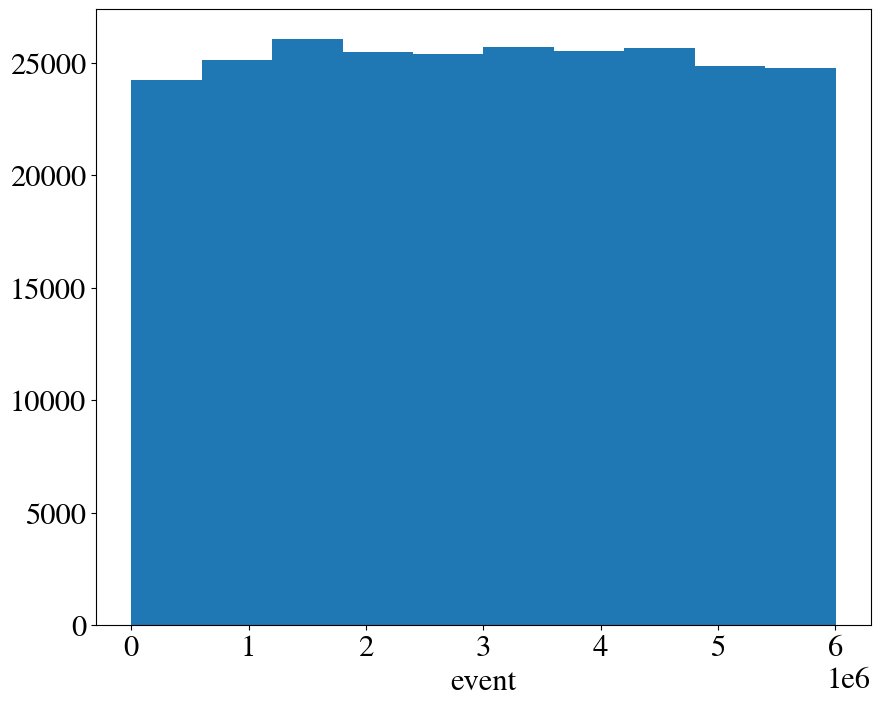

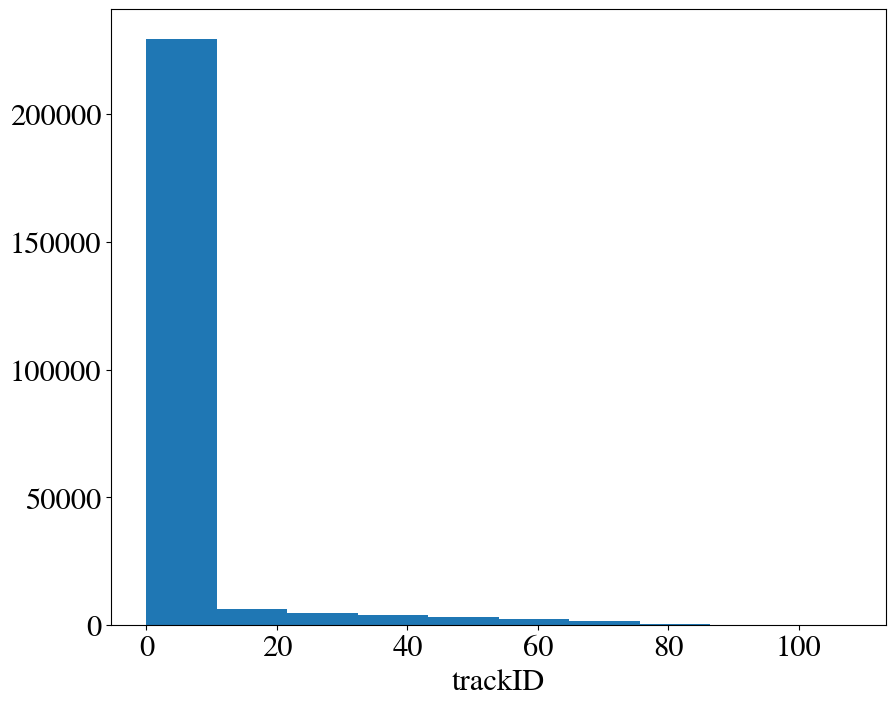

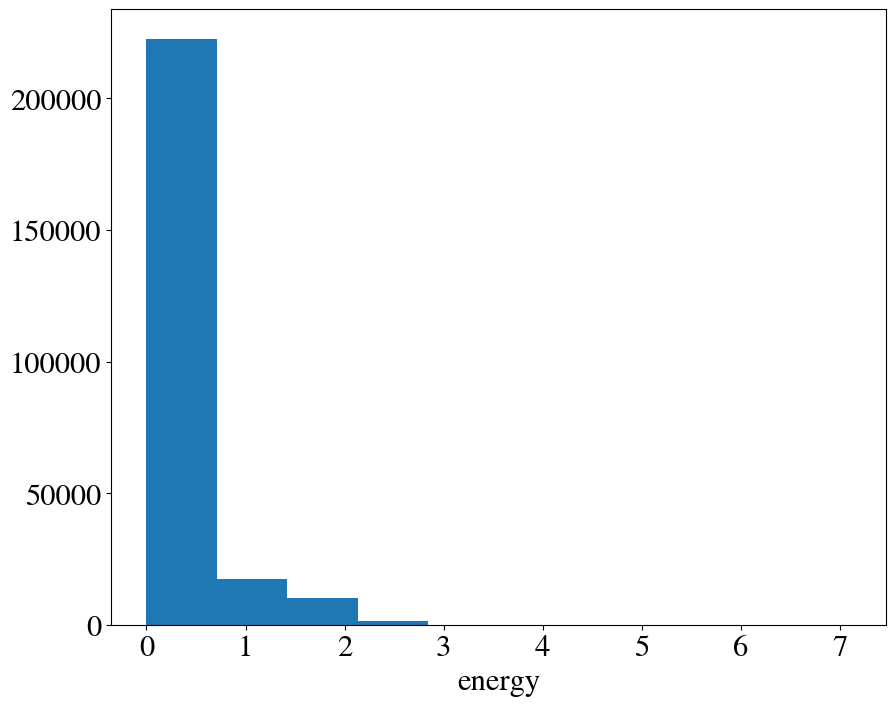

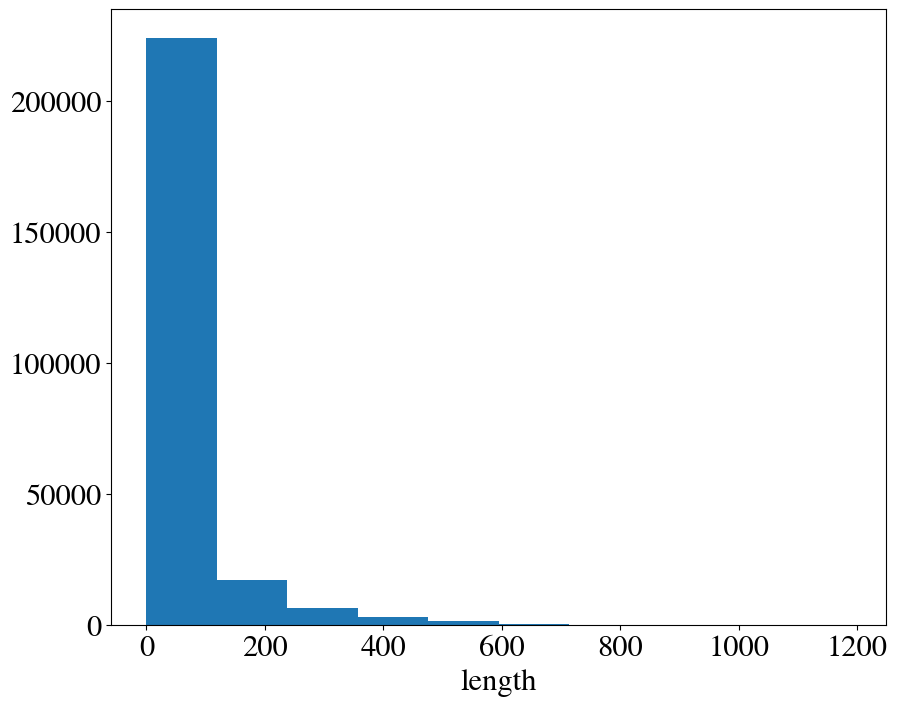

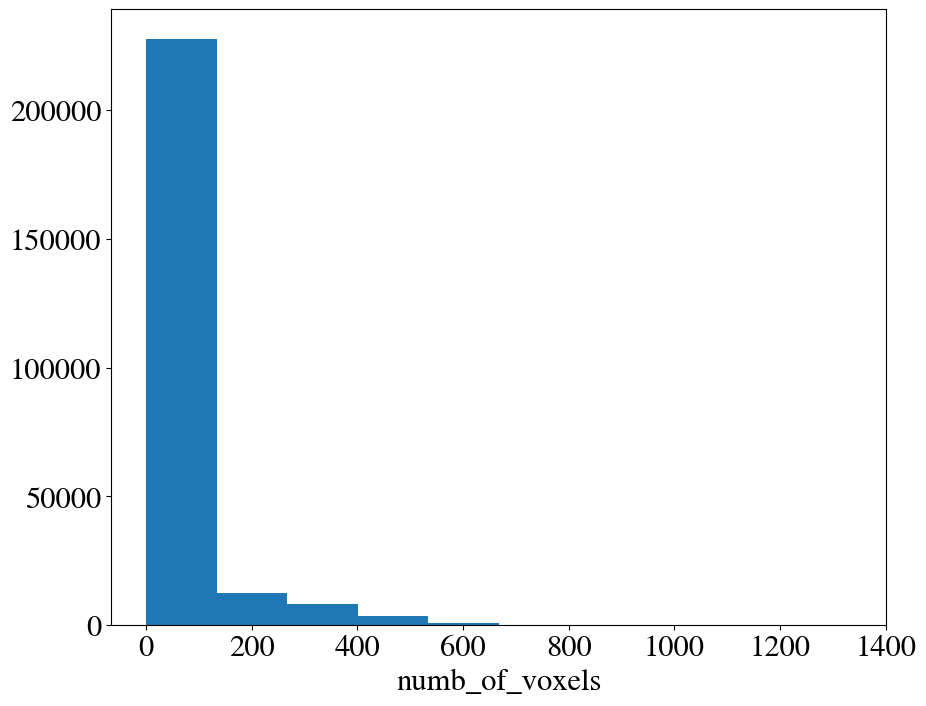

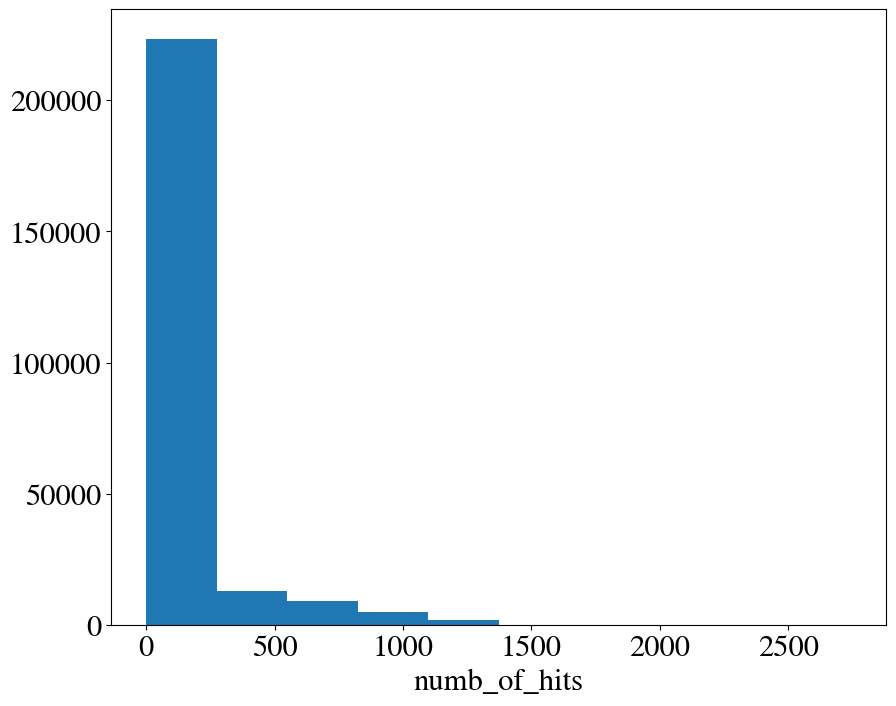

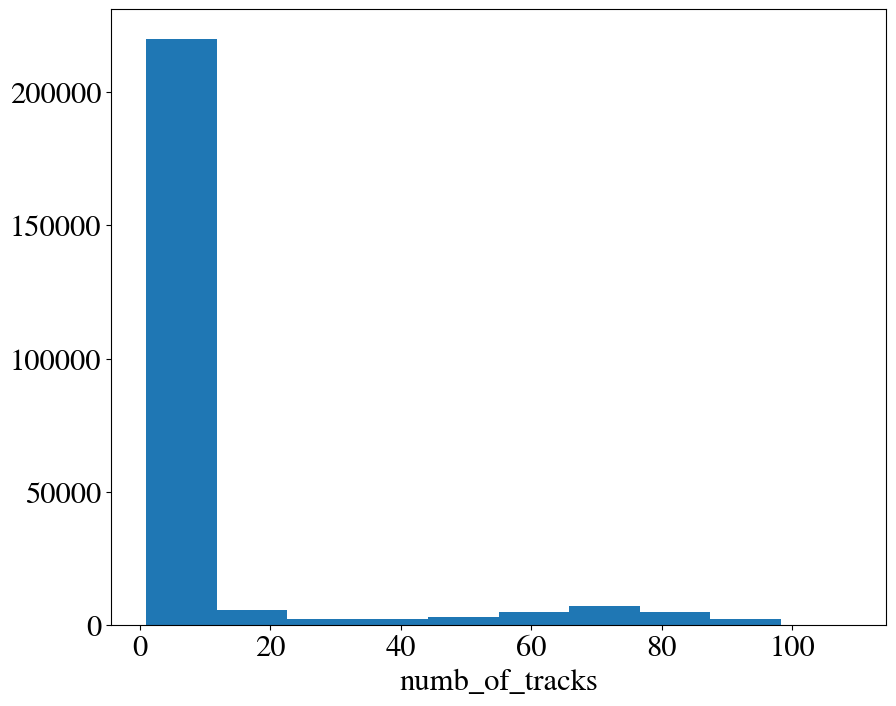

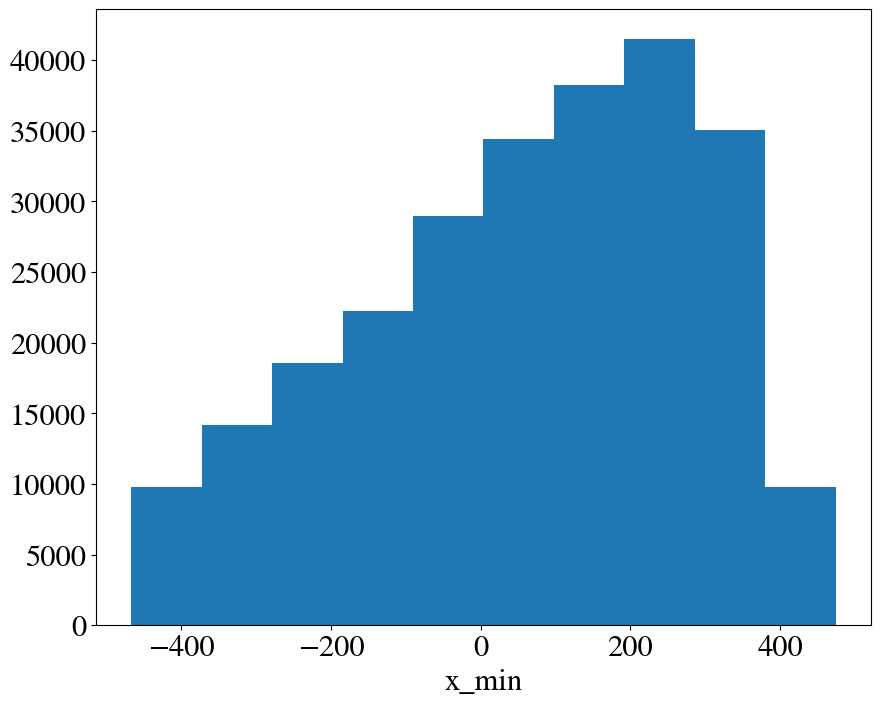

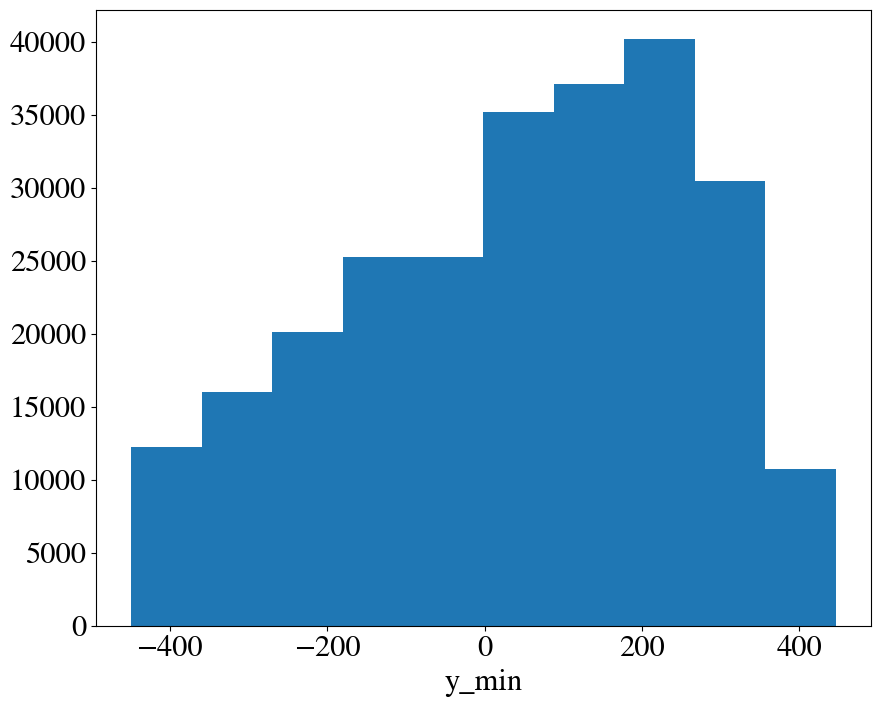

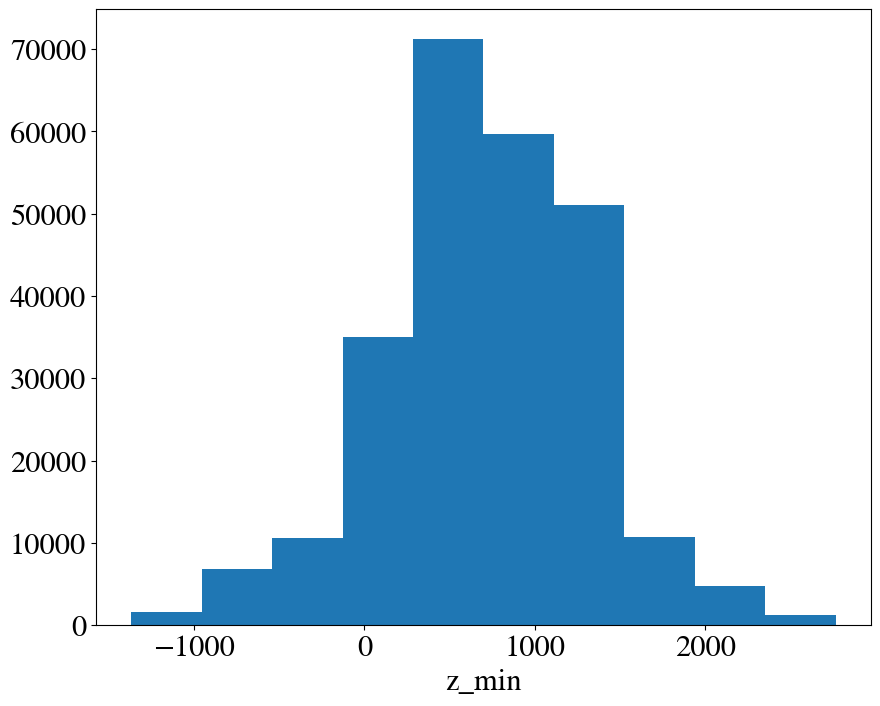

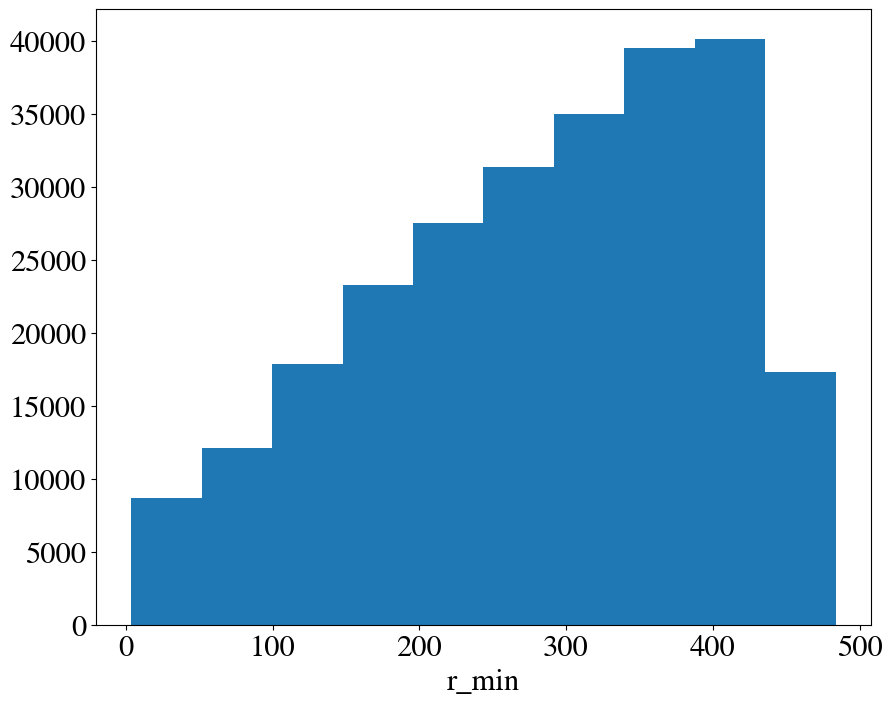

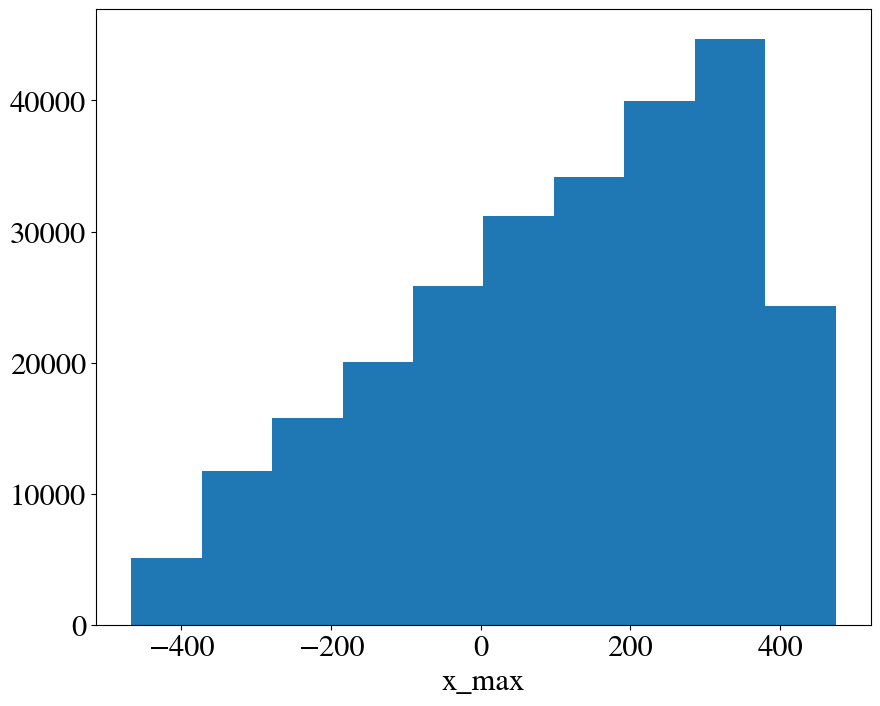

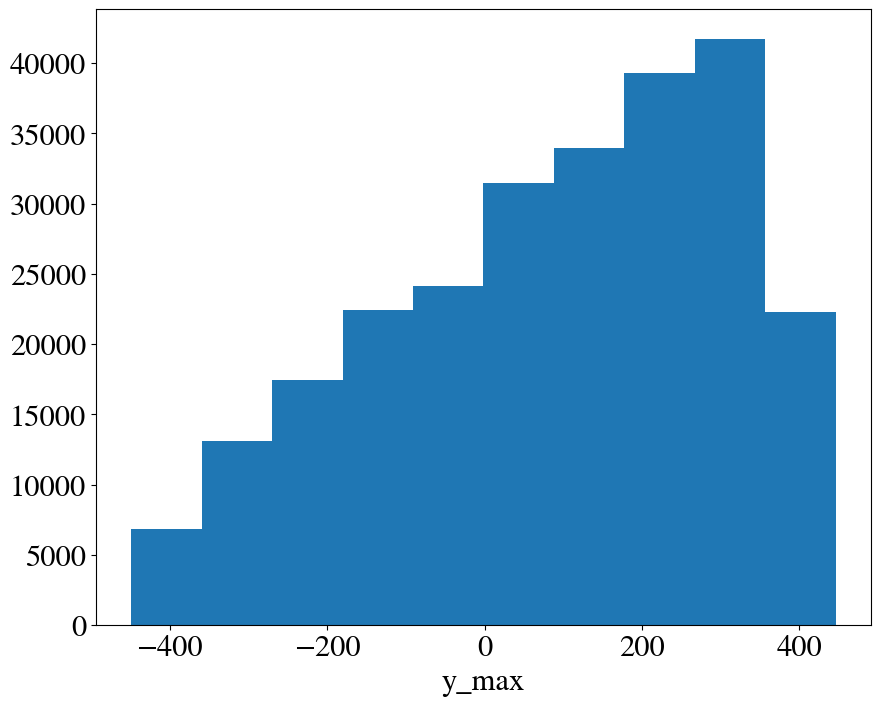

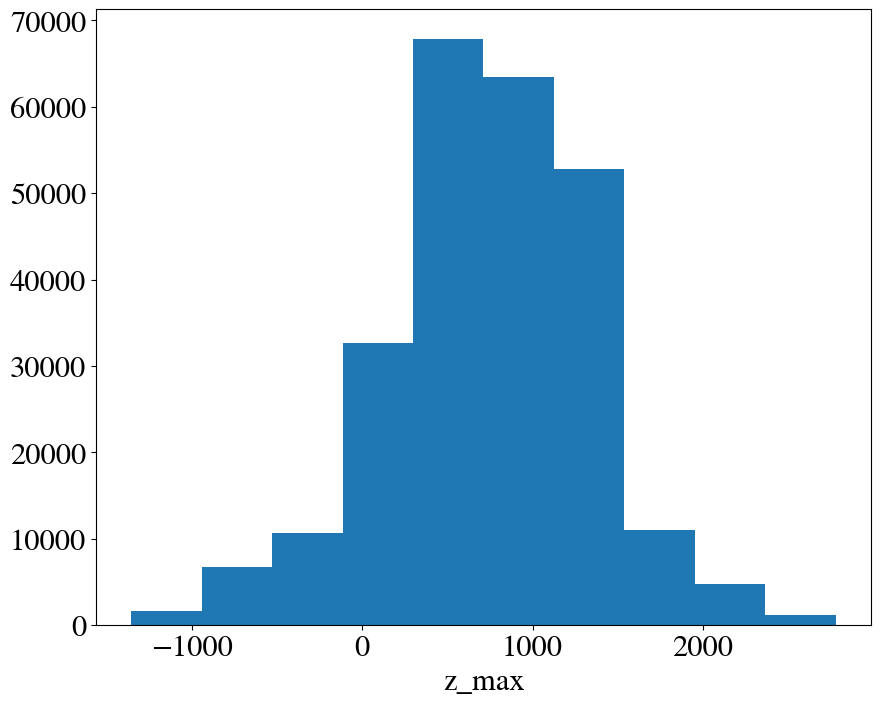

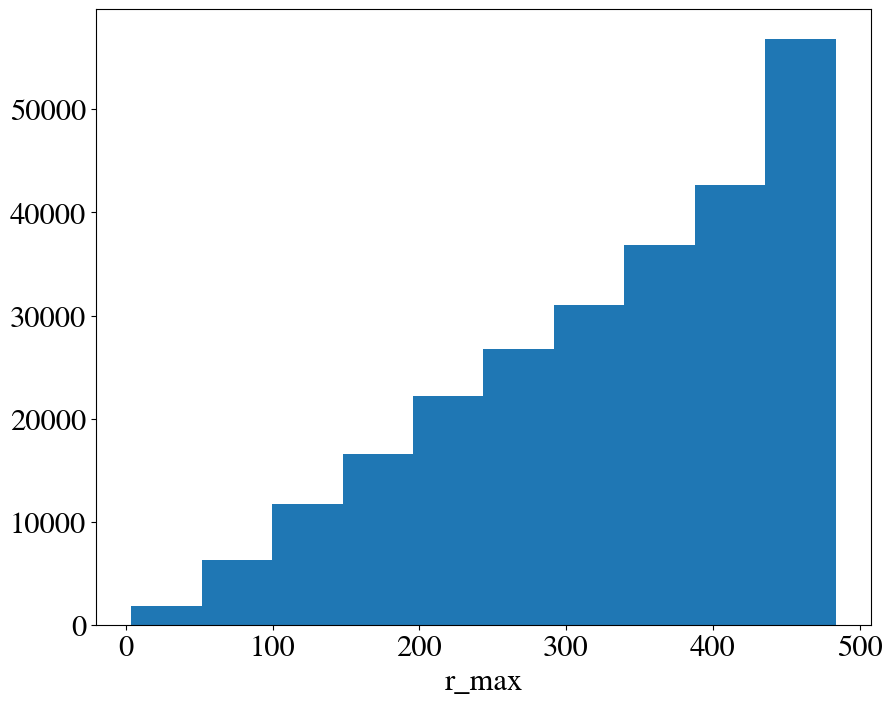

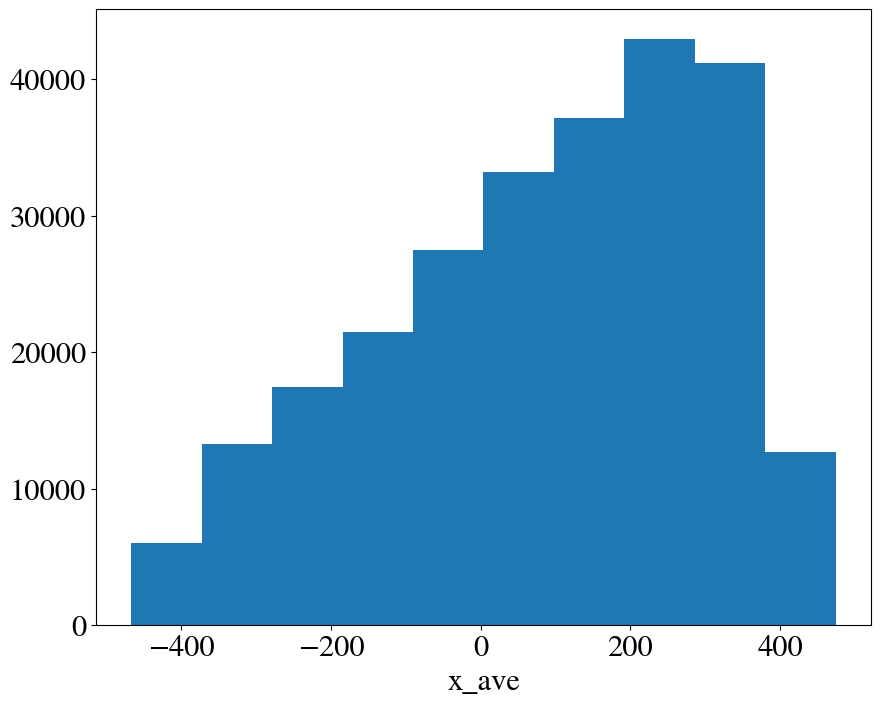

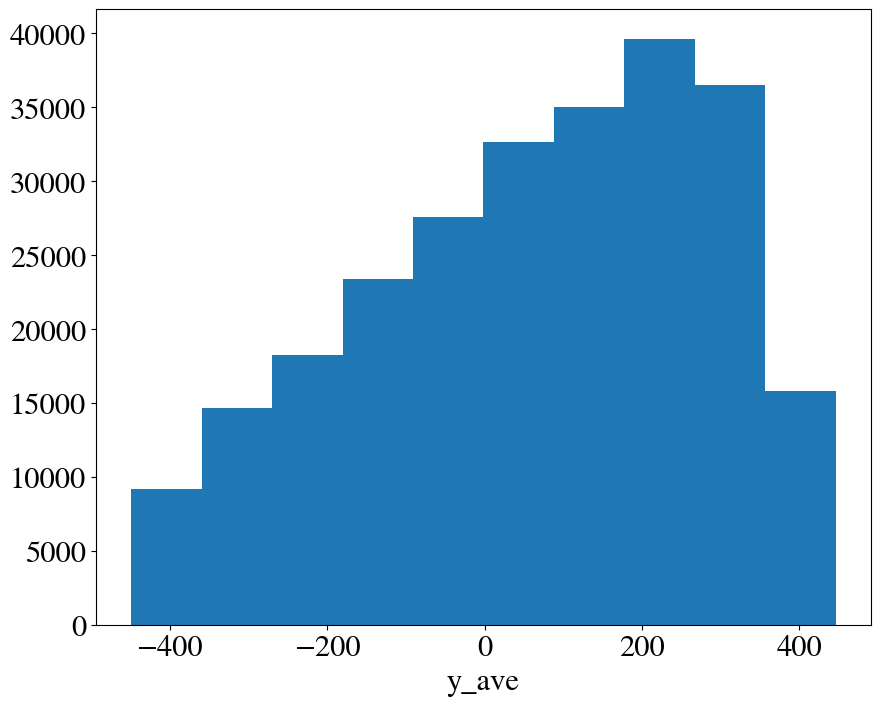

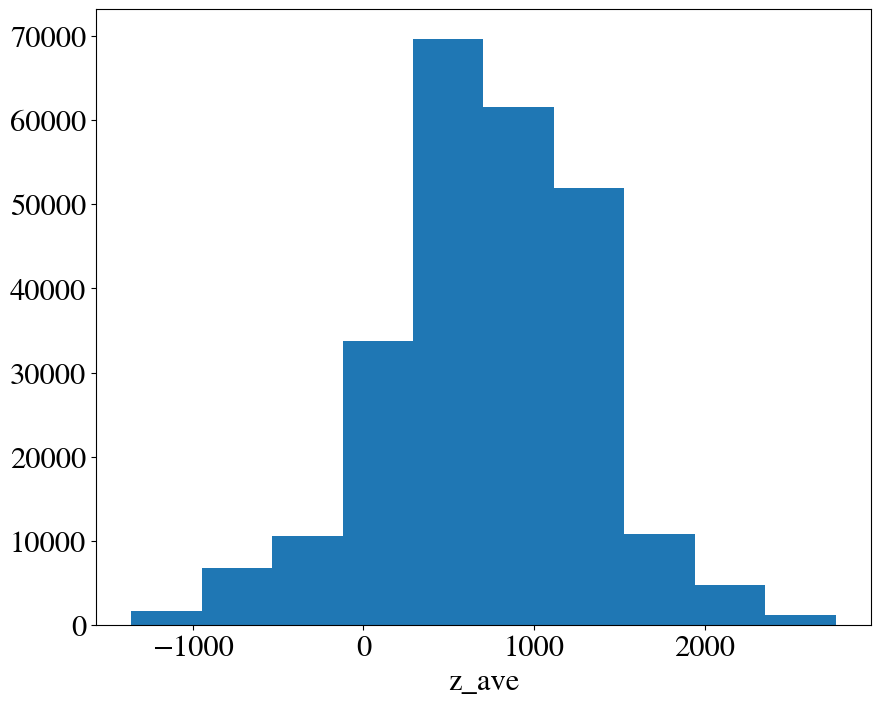

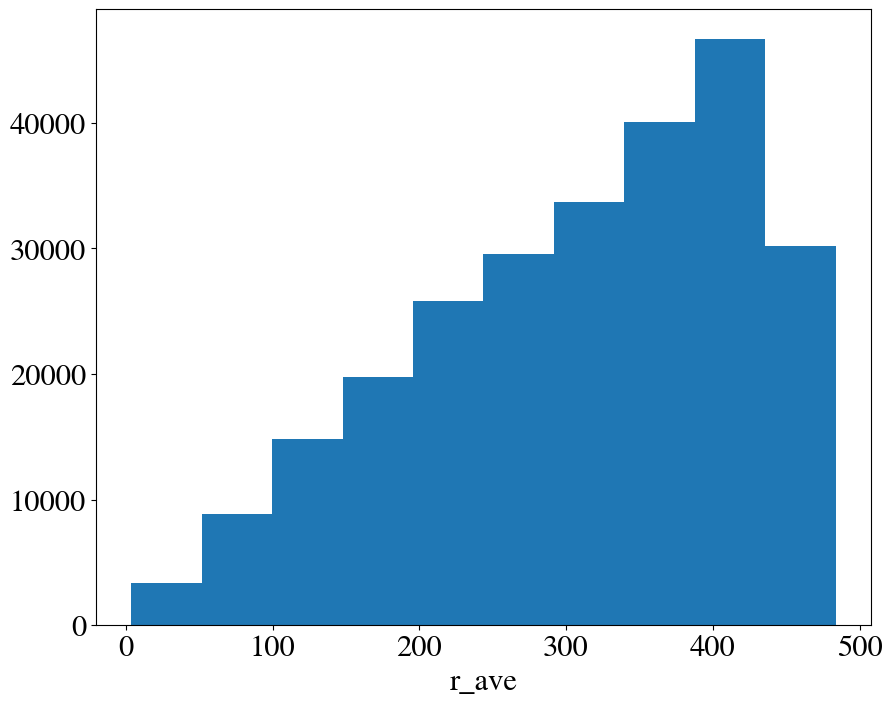

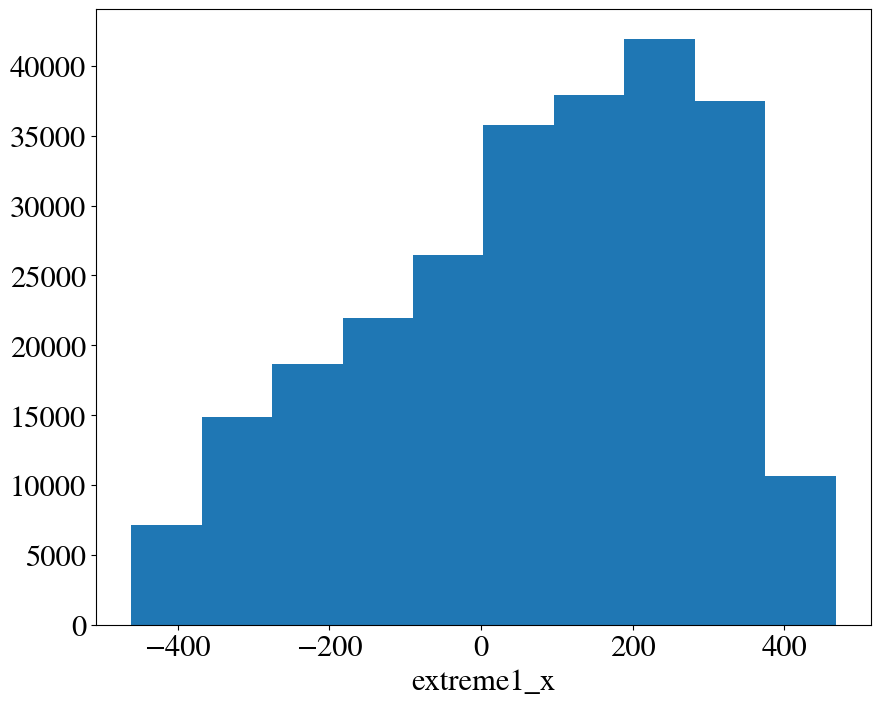

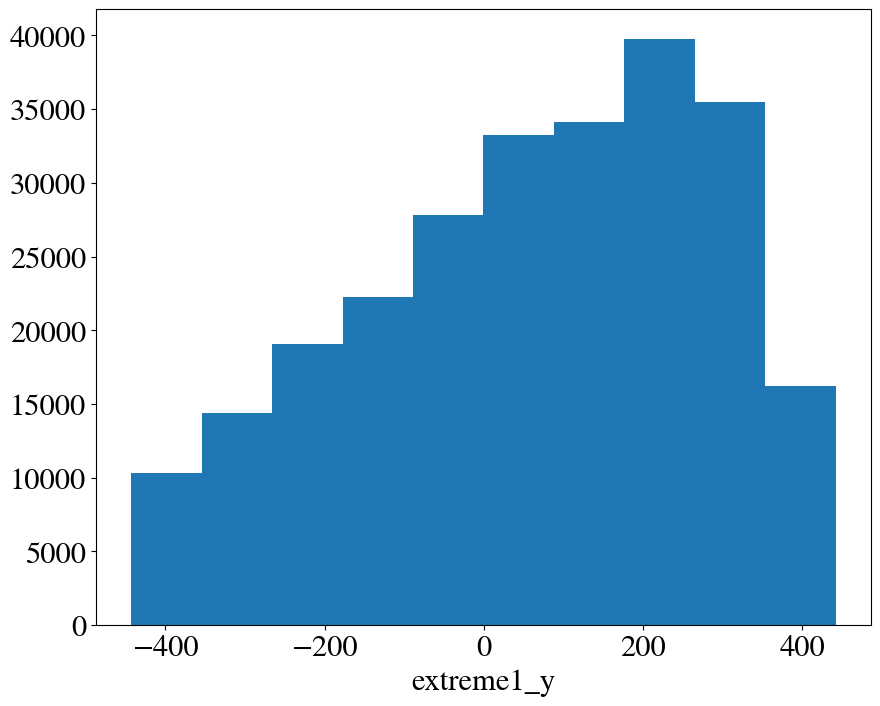

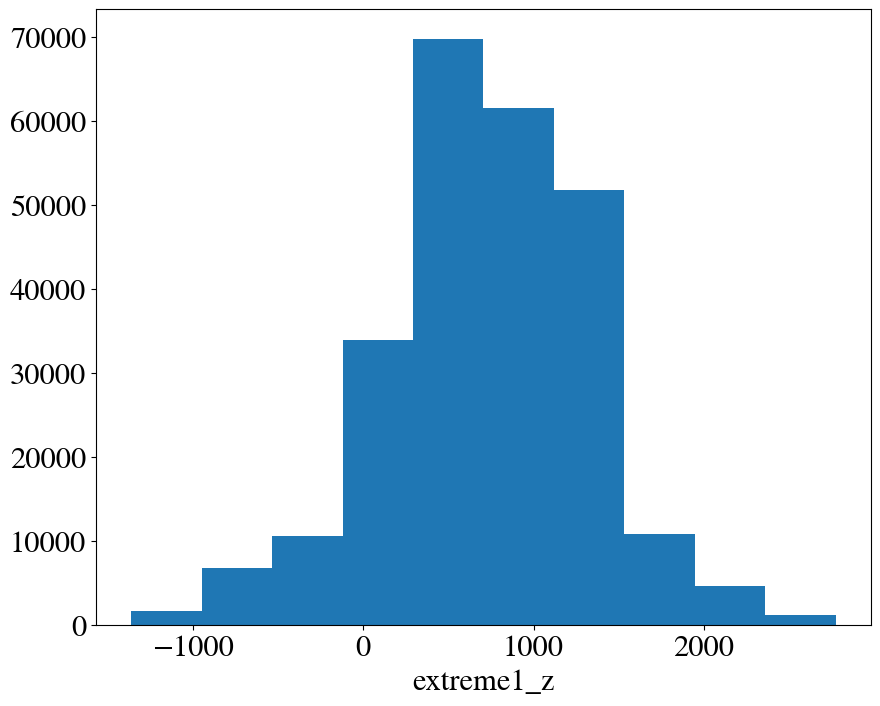

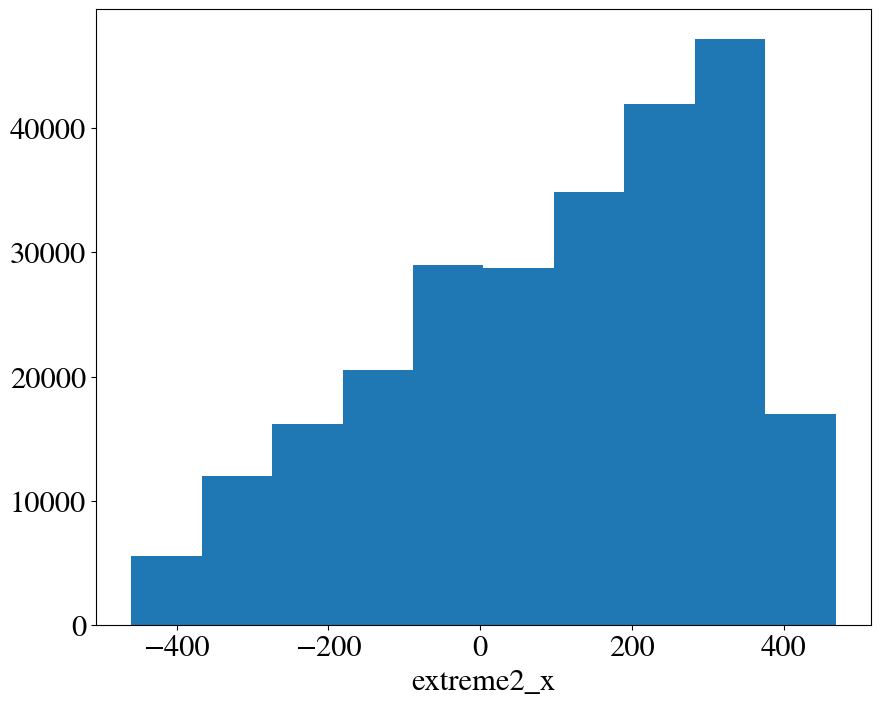

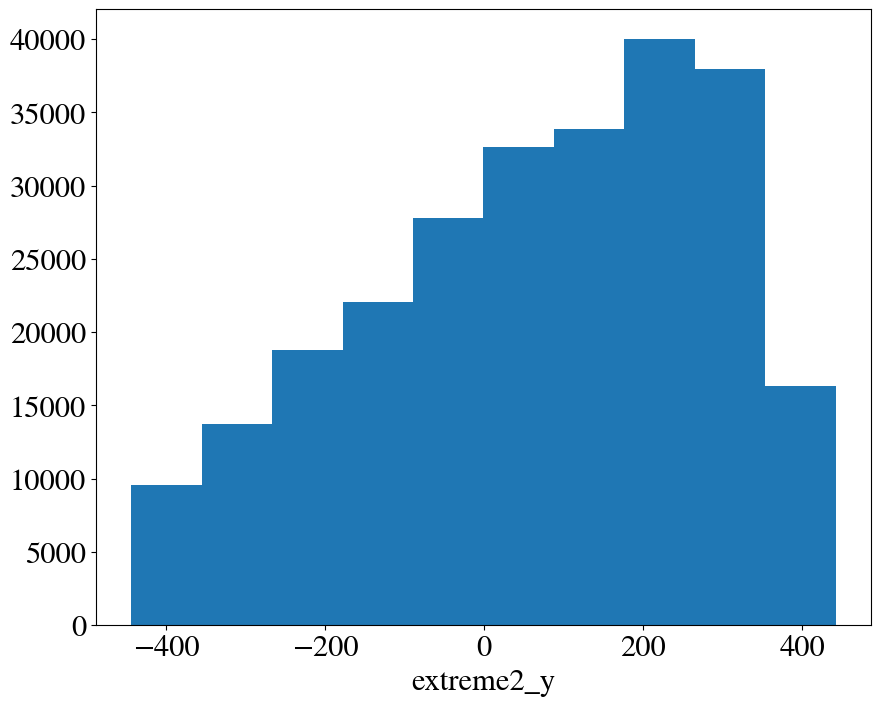

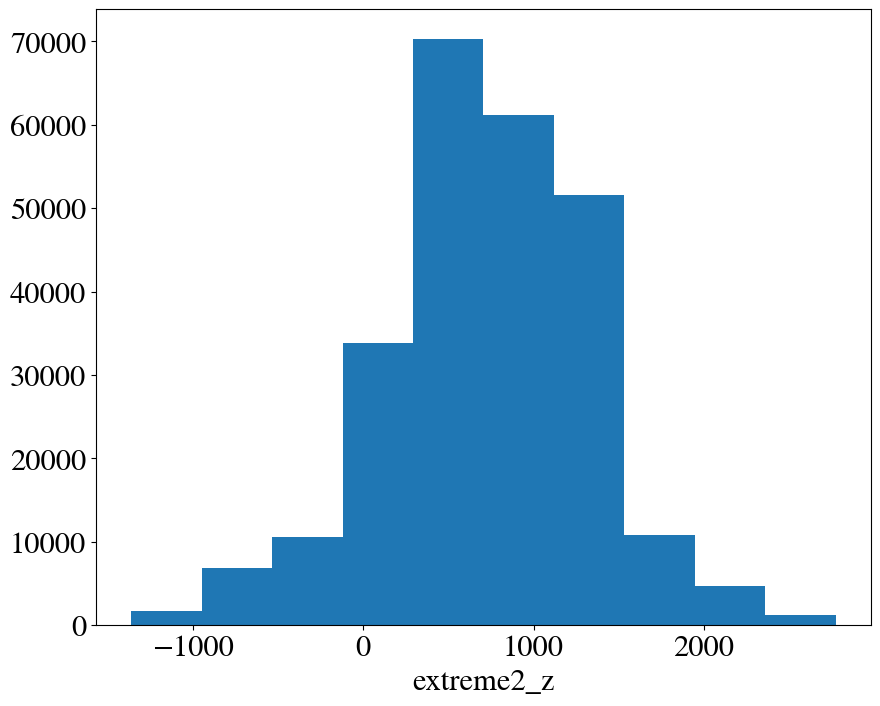

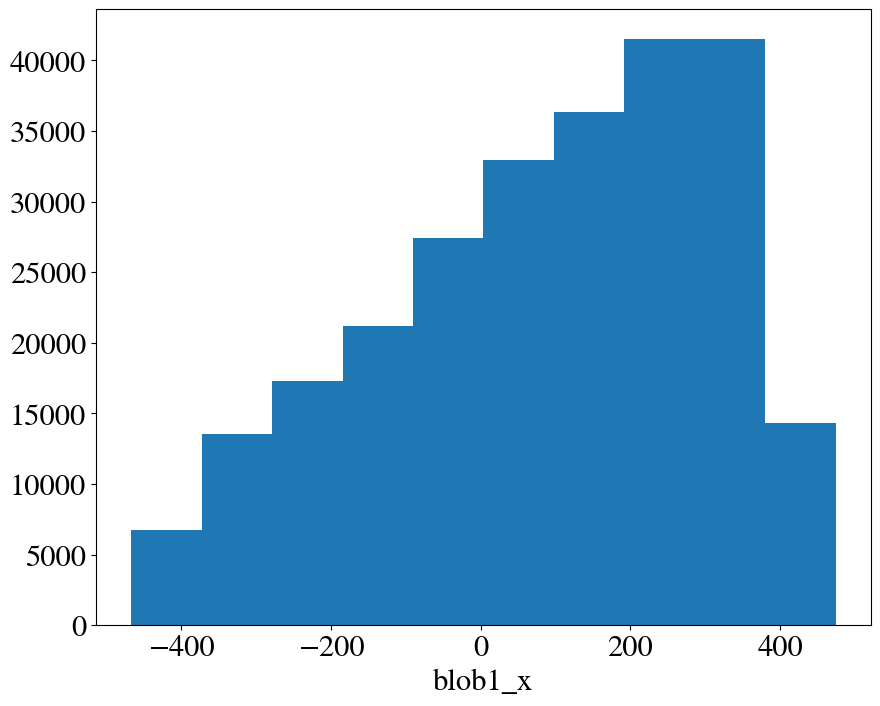

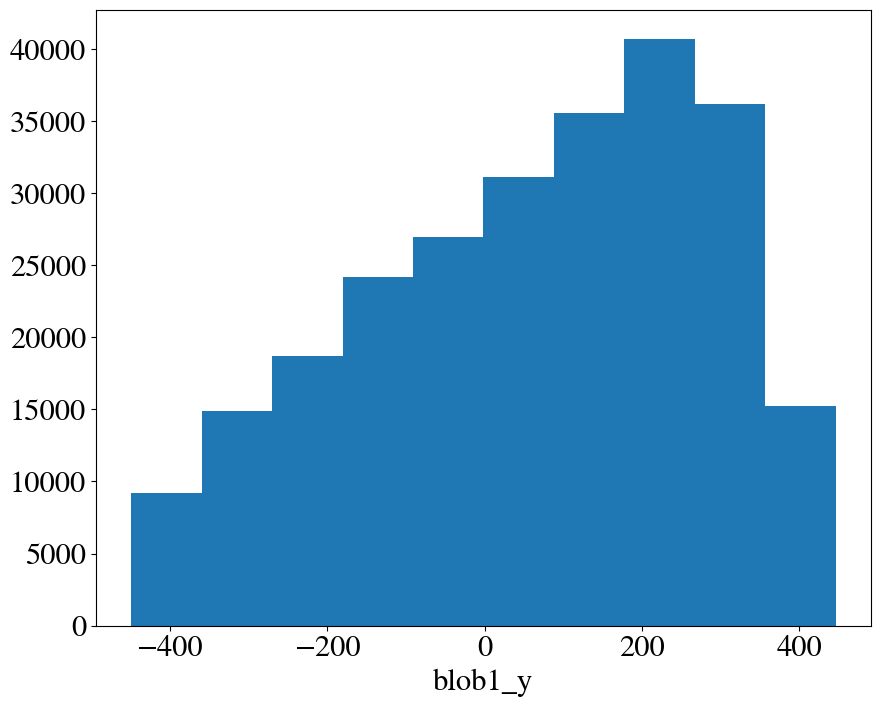

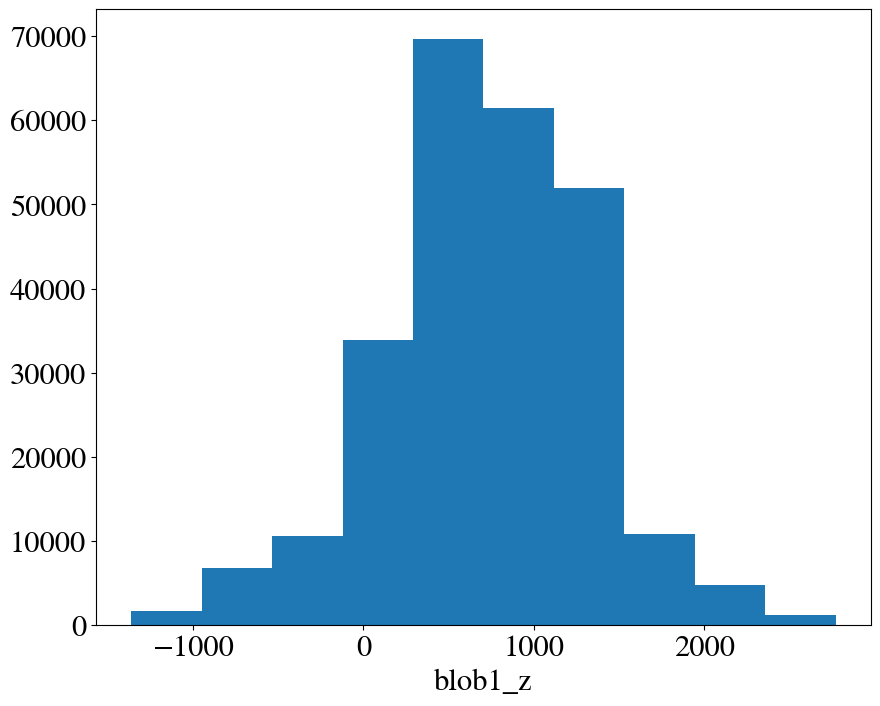

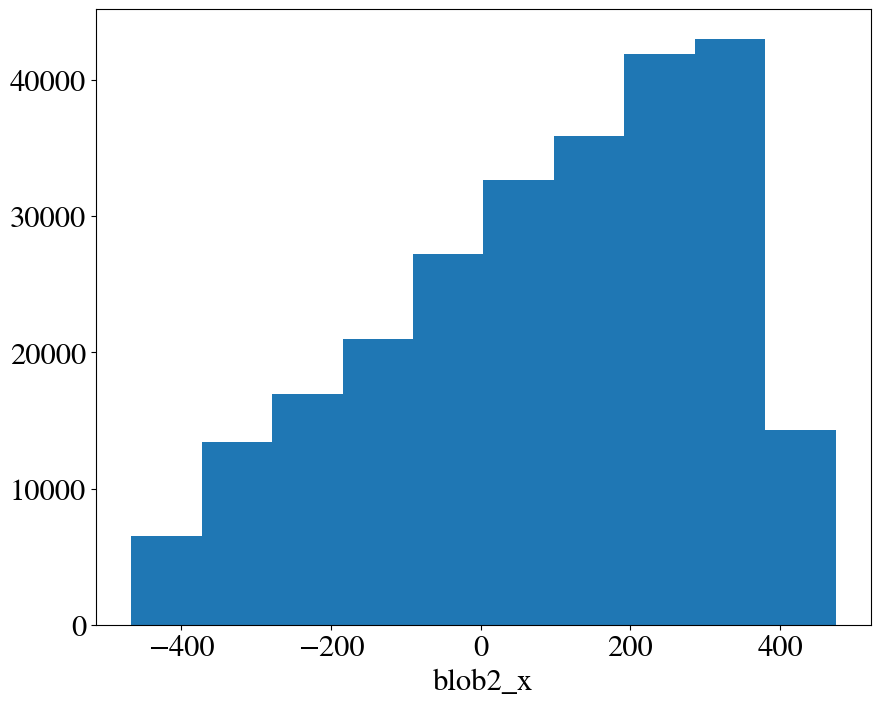

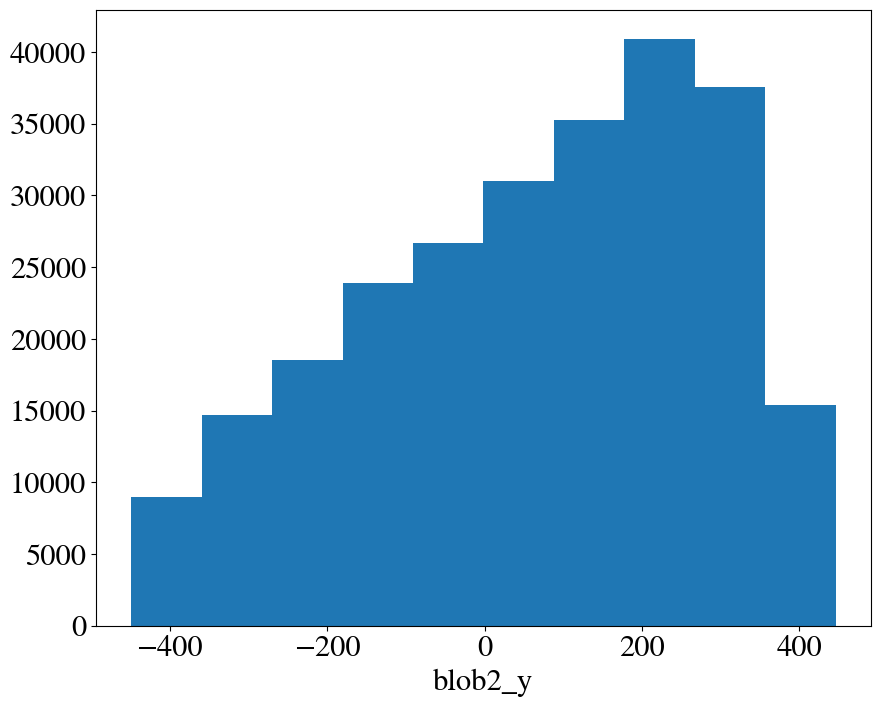

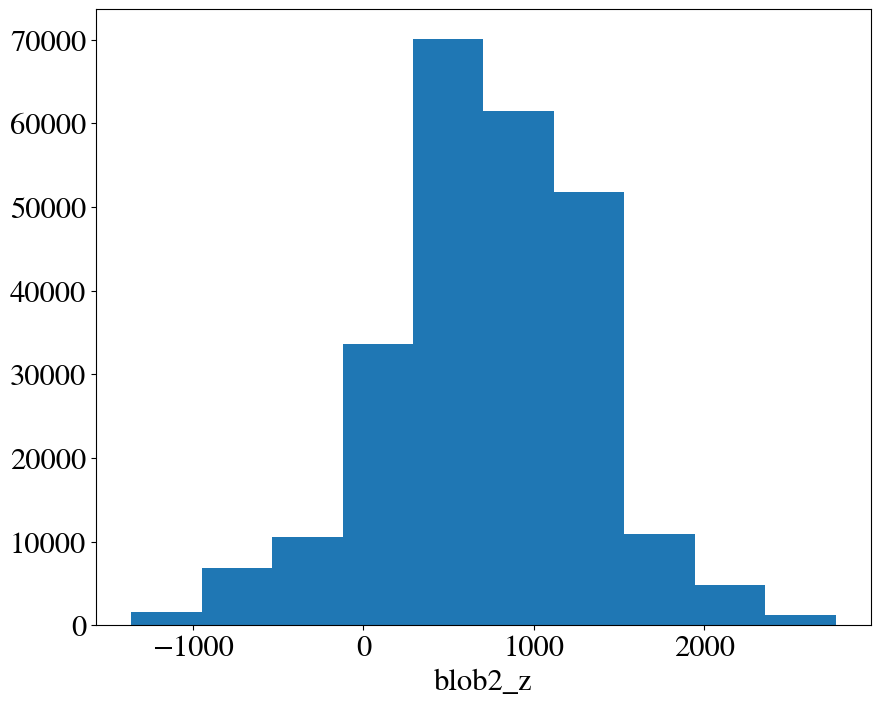

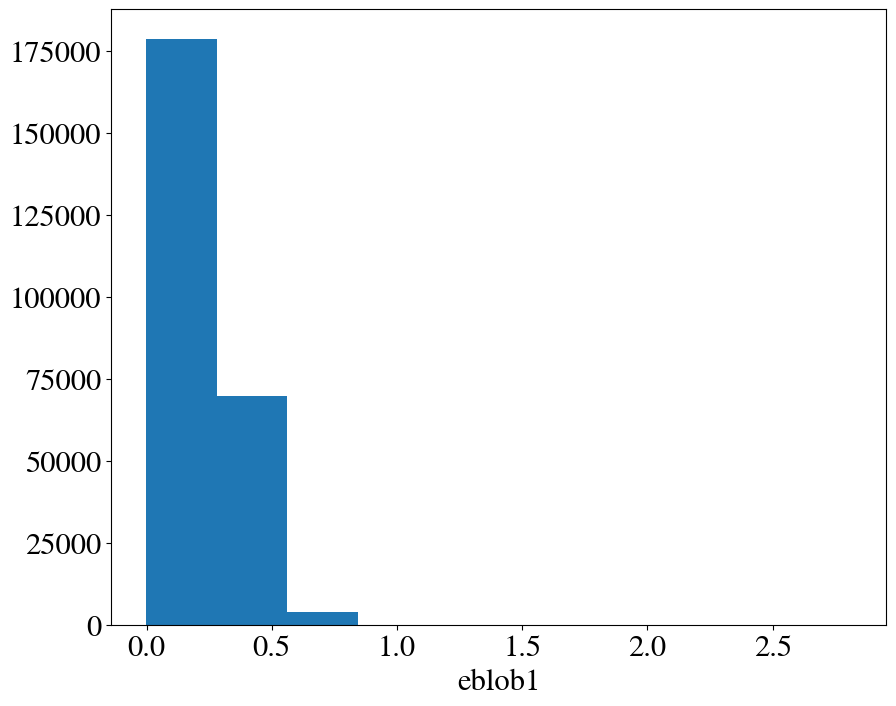

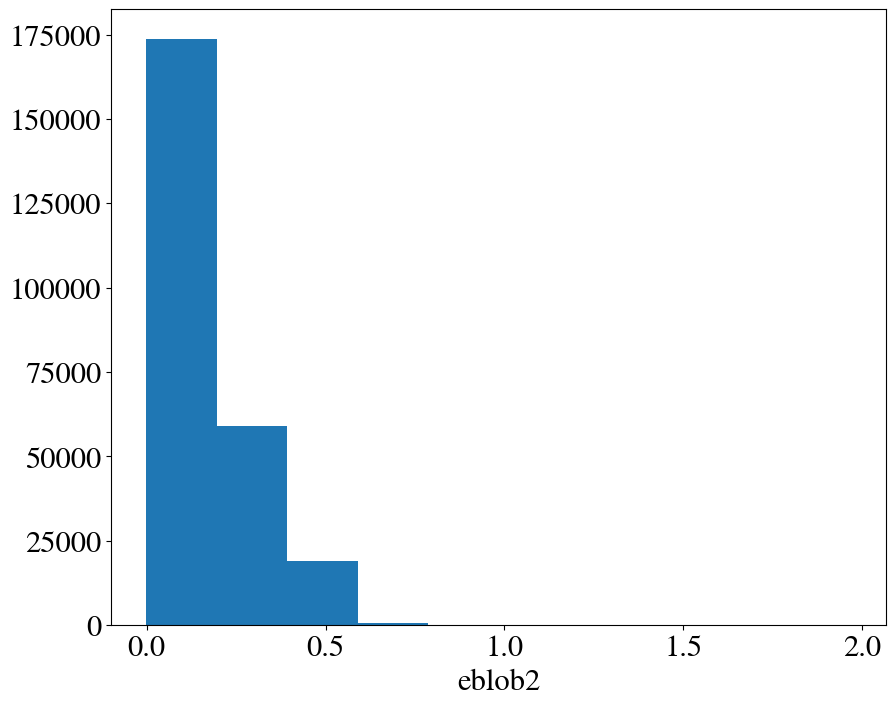

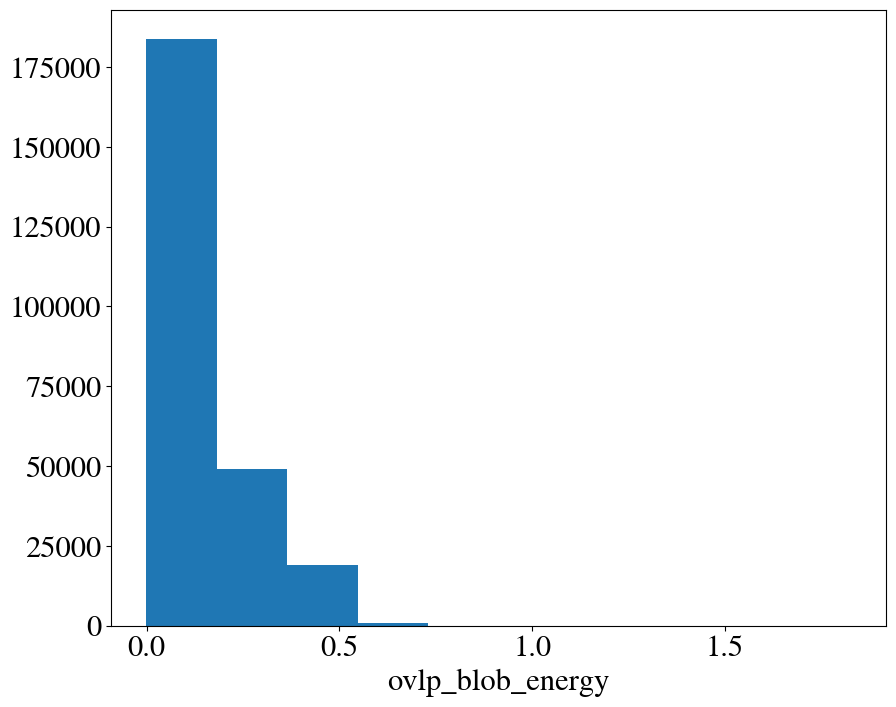

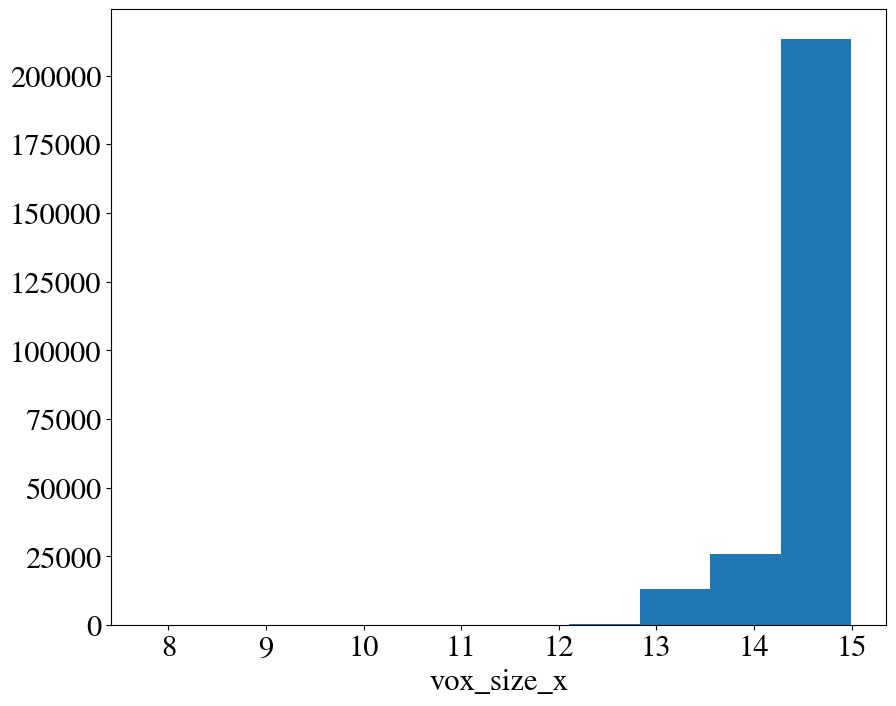

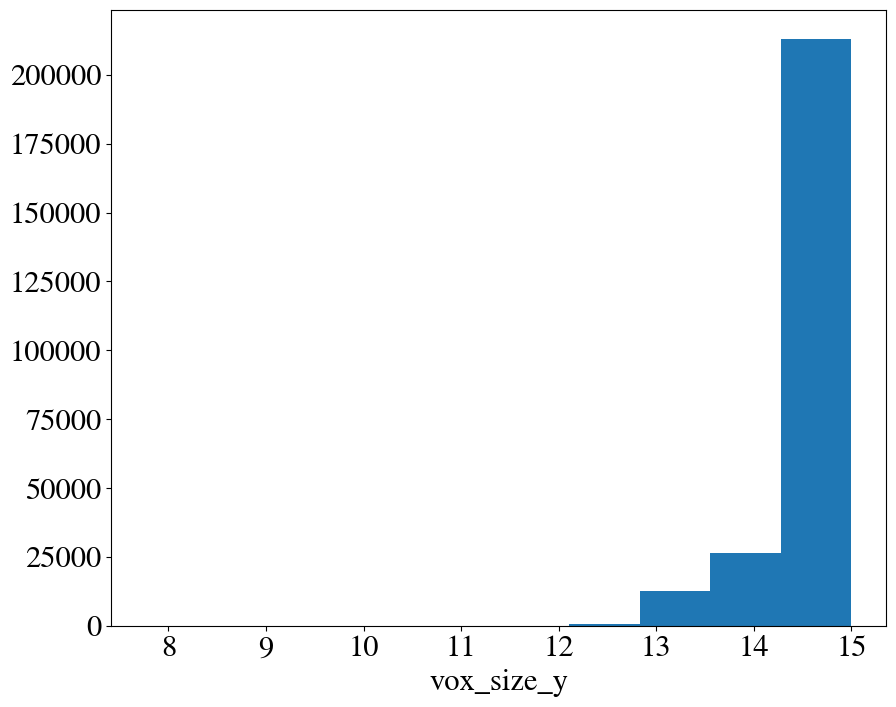

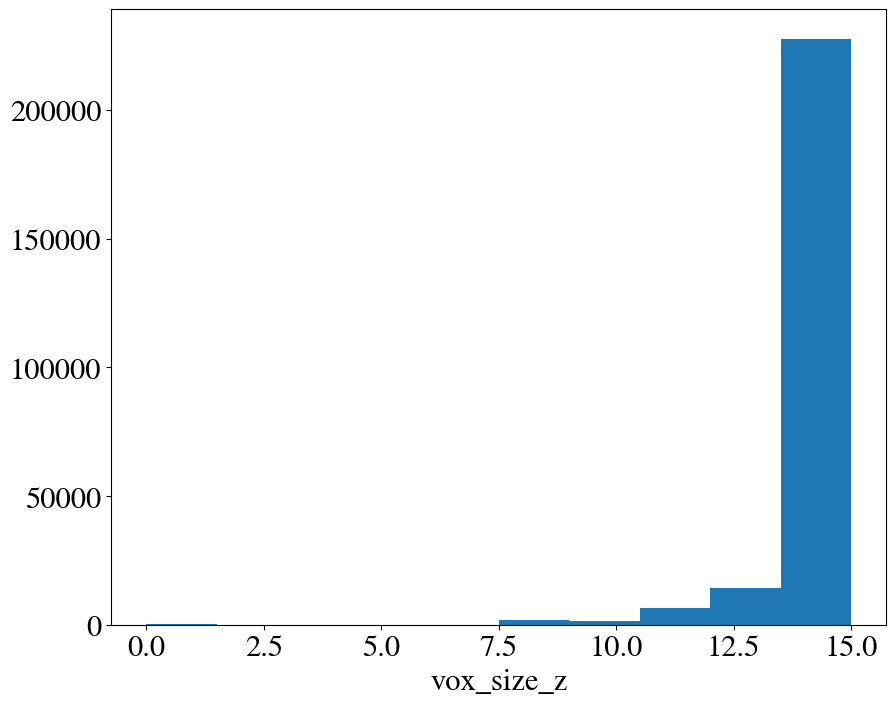

In [21]:
for col in dst_sensor_dropper_10PE.columns:
    plt.hist(dst_sensor_dropper_10PE[col])
    plt.xlabel(col)
    plt.show()

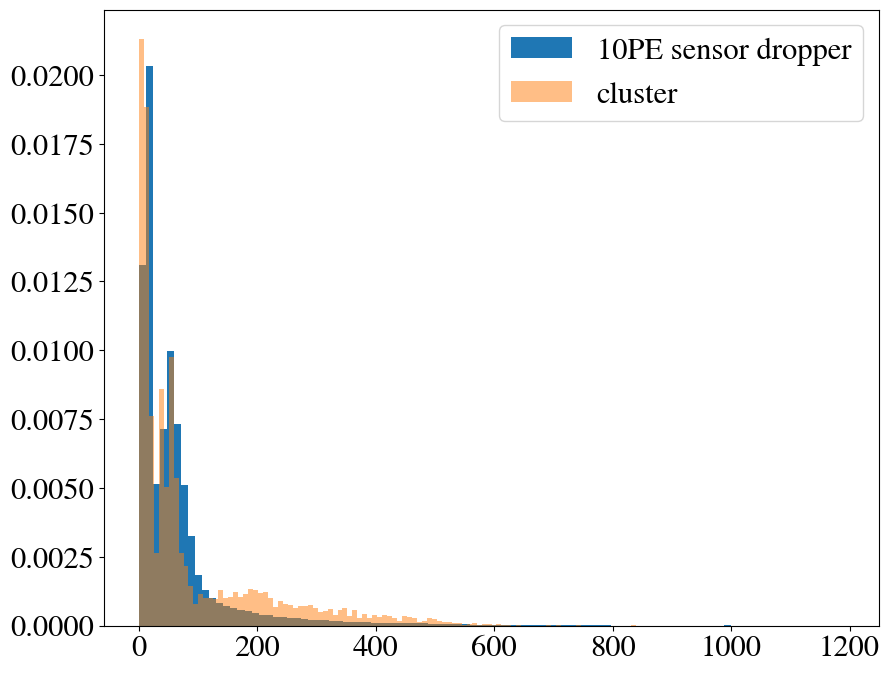

In [46]:
plt.hist(dst_sensor_dropper_10PE['length'], label = '10PE sensor dropper', bins = 100, density = True)
plt.hist(dst_cluster_dropper['length'], label = 'cluster', bins = 100, density = True, alpha = 0.5)
plt.legend()
plt.show()

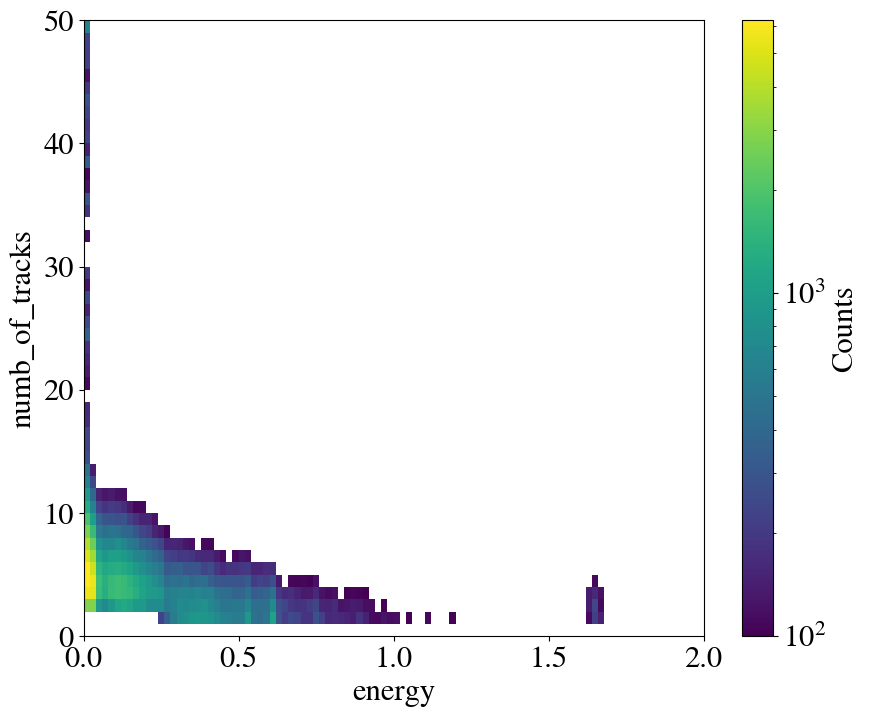

In [65]:
y_axis = 'numb_of_tracks'
x_axis = 'energy'
from matplotlib.colors import LogNorm

dataset = dst_sensor_dropper_10PE

plt.hist2d(
    dataset[x_axis],
    dataset[y_axis],
    bins=[100, 50],
    range=[[0, 2], [0, 50]],
    norm=LogNorm(),
    cmin=100,          # empty bins are masked (log(0) is undefined)
)
plt.colorbar(label="Counts")
#plt.hist(dst_cluster_dropper['length'], label = 'cluster', bins = 100, density = True, alpha = 0.5)
#plt.legend()
plt.xlabel(x_axis)
plt.ylabel(y_axis)
plt.show()

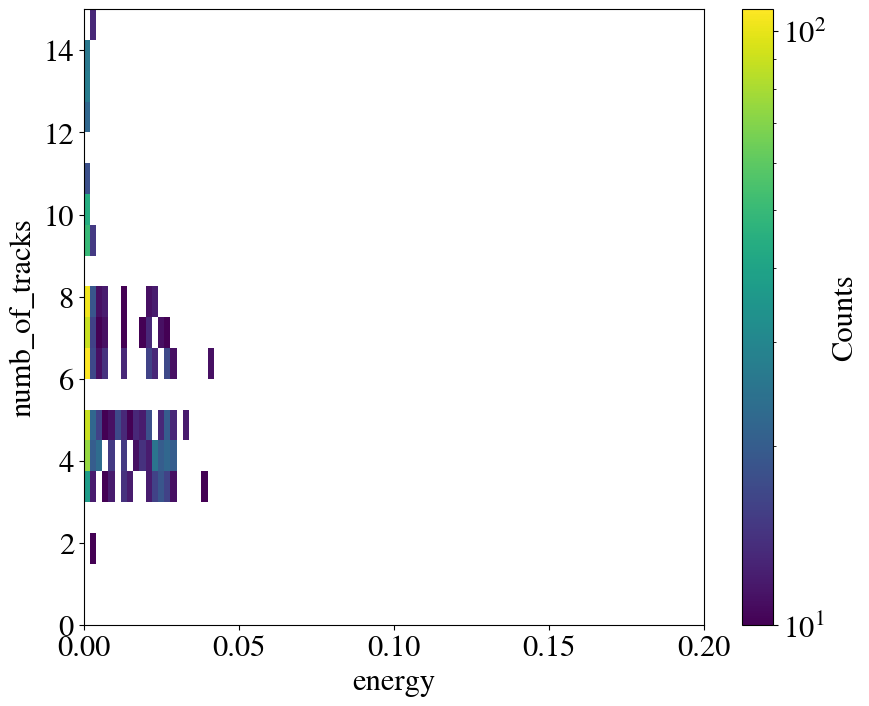

In [97]:
y_axis = 'numb_of_tracks'
x_axis = 'energy'
from matplotlib.colors import LogNorm

dataset = dst_cluster_dropper

plt.hist2d(
    dataset[x_axis],
    dataset[y_axis],
    bins=[100, 20],
    range=[[0, 0.2], [0, 15]],
    norm=LogNorm(),
    cmin=10,          # empty bins are masked (log(0) is undefined)
)
plt.colorbar(label="Counts")
#plt.hist(dst_cluster_dropper['length'], label = 'cluster', bins = 100, density = True, alpha = 0.5)
#plt.legend()
plt.xlabel(x_axis)
plt.ylabel(y_axis)
plt.show()

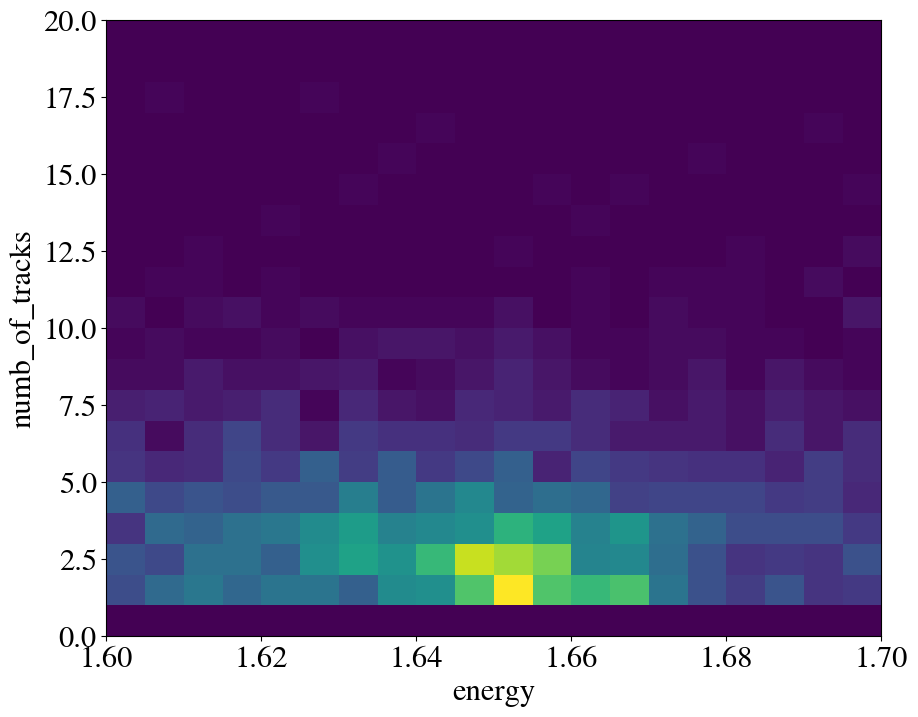

In [132]:
dataset = dst_sensor_dropper_10PE
#dataset = dst_cluster_dropper


x_axis = 'energy'
y_axis = 'numb_of_tracks'
plt.hist2d(dataset[x_axis], dataset[y_axis], range = [[1.6,1.7],[0, 20]], bins = [20, 20])#, s = 1)

plt.xlabel(x_axis)
plt.ylabel(y_axis)
plt.show()

In [82]:
print(dst_sensor_dropper_10PE['length'].mean())
print(dst_cluster_dropper['length'].mean())

61.48877619321125
91.72375990017646


In [ ]:
### plt.hist(dst_sensor_dropper_10PE['numb_of_tracks'], label = '10PE sensor dropper', bins = 100, density = True)
plt.hist(dst_cluster_dropper['numb_of_tracks'], label = 'cluster', bins = 100, density = True, alpha = 0.5)
plt.legend()
plt.show()

In [122]:
# DEP data
sensor_dropper_10PE_DEP = dst_sensor_dropper_10PE[dst_sensor_dropper_10PE.energy < 1.8]
sensor_dropper_10PE_DEP = sensor_dropper_10PE_DEP[sensor_dropper_10PE_DEP.energy > 1.6]

cluster_dropper_DEP = dst_cluster_dropper[dst_cluster_dropper.energy < 1.8]
cluster_dropper_DEP = cluster_dropper_DEP[cluster_dropper_DEP.energy > 1.6]

In [70]:
print(sensor_dropper_10PE_DEP['length'].mean())
print(cluster_dropper_DEP['length'].mean())

250.42874411237628
236.7171743402388


In [35]:
display(cluster_dropper_DEP)
display(sensor_dropper_10PE_DEP)

,event,trackID,energy,length,numb_of_voxels,numb_of_hits,numb_of_tracks,x_min,y_min,z_min,...,blob1_z,blob2_x,blob2_y,blob2_z,eblob1,eblob2,ovlp_blob_energy,vox_size_x,vox_size_y,vox_size_z
0,915224,0,1.540521,242.883484,378,902,1,257.775,-1.375,316.0,...,334.117707,319.975,45.275,413.503370,0.410805,0.302114,0.0,14.453125,14.672500,14.500000
0,310991,0,1.632803,364.291641,581,1366,11,-220.275,245.925,956.0,...,1006.103070,-189.175,276.025,1279.416388,0.202453,0.073981,0.0,14.687209,14.826923,14.927536
0,5339679,0,1.689644,242.500603,519,1364,1,212.125,-294.825,1288.0,...,1321.465112,304.425,-93.675,1337.675197,0.370818,0.308865,0.0,14.380000,14.706818,14.000000
0,2528717,0,1.626605,347.727814,548,1258,3,-312.575,-78.625,620.0,...,673.762867,-65.775,122.525,773.849437,0.366664,0.098764,0.0,14.765217,14.893103,14.400000
2,3114673,0,1.618363,300.909119,598,1409,5,-435.975,-32.475,1072.0,...,1094.067606,-328.125,45.275,1242.778646,0.280293,0.094154,0.0,14.862963,14.826923,14.400000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
0,2972846,0,1.501343,266.216629,408,1023,1,-173.625,-0.875,616.0,...,651.981266,26.525,152.625,697.691921,0.460235,0.117314,0.0,14.672500,14.453125,14.222222
10,2973126,0,1.654404,164.860556,328,856,1,88.725,-202.025,256.0,...,305.113565,165.475,-155.375,290.309290,0.575995,0.315990,0.0,14.296429,14.453125,13.714286
0,641524,0,1.521484,200.928835,356,886,2,-19.125,322.675,664.0,...,684.067198,73.175,353.775,812.190441,0.454747,0.387458,0.0,14.975000,14.797917,14.000000
0,2283787,0,1.660266,226.393836,428,1062,1,-158.075,-448.825,616.0,...,679.584143,10.975,-386.625,665.511469,0.361445,0.355689,0.0,14.714286,14.367857,14.000000


,event,trackID,energy,length,numb_of_voxels,numb_of_hits,numb_of_tracks,x_min,y_min,z_min,...,blob1_z,blob2_x,blob2_y,blob2_z,eblob1,eblob2,ovlp_blob_energy,vox_size_x,vox_size_y,vox_size_z
4,927110,0,1.577780,230.440749,332,831,6,73.175,168.175,1228.0,...,1314.343944,243.225,276.025,1252.957297,0.372887,0.327739,0.00000,14.979167,14.756250,14.929577
8,2133434,0,1.562466,373.829073,226,470,6,104.275,-278.775,992.0,...,995.477014,366.625,-109.225,1040.577975,0.557029,0.318342,0.00000,14.706818,14.710465,14.888889
30,4074954,0,1.657297,203.230714,311,770,3,73.175,-155.375,212.0,...,351.053284,134.375,-16.425,234.190726,0.424064,0.187801,0.00000,14.170833,14.200000,14.545455
20,1597990,0,1.591190,370.712922,359,837,1,227.675,106.475,528.0,...,550.160204,319.975,292.075,649.313829,0.475345,0.107055,0.00000,13.895000,14.453125,14.571429
21,1598067,0,1.600085,166.528185,233,667,5,57.625,322.675,512.0,...,562.936722,149.925,383.875,594.407038,0.539493,0.448103,0.00000,14.898333,14.808000,14.829268
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
25,1704033,0,1.534597,153.689917,185,508,6,42.075,-217.575,868.0,...,982.941808,88.725,-155.375,893.168761,0.520380,0.465842,0.00000,14.792857,14.725556,14.971429
4,1363784,0,1.580394,248.761528,400,960,6,88.725,-78.625,304.0,...,324.312808,304.425,-16.925,340.123061,0.216519,0.171505,0.00000,14.710465,14.975000,14.800000
5,545071,0,1.650642,130.425102,167,474,6,-220.275,122.525,148.0,...,186.964077,-173.625,199.275,200.628870,0.829018,0.501689,0.13550,14.690476,14.413333,14.961039
25,545134,0,1.614555,542.535768,512,1113,5,-173.625,-47.525,760.0,...,1071.116376,-3.575,168.175,780.092498,0.357492,0.133048,0.00000,14.887500,14.910345,14.518519


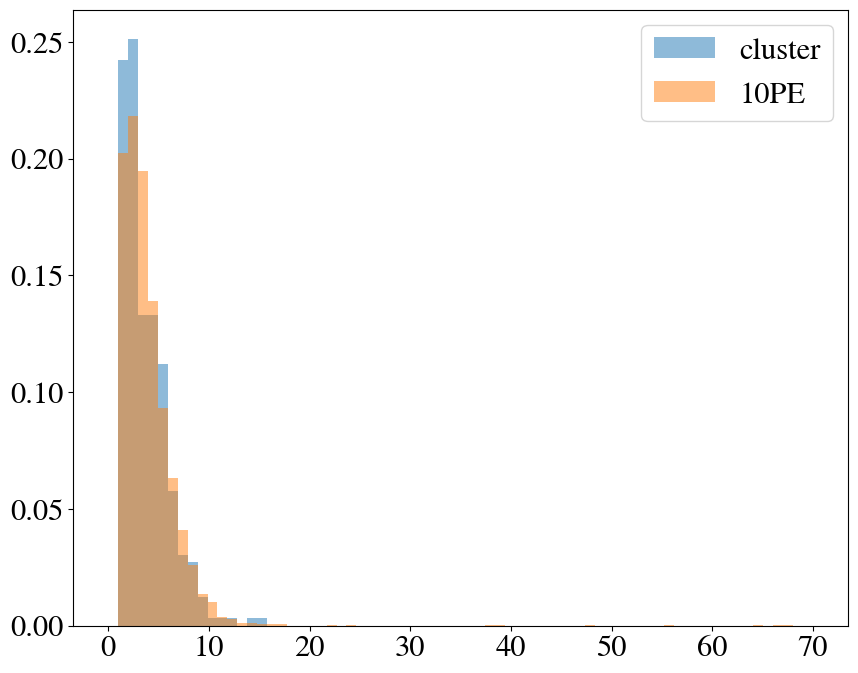

Ratio of 1-tracks in DEP for clusters / sensor dropper:

Cluster dropper 0.3137254901960784
1.2583537082314589
10 PEs 0.24931423346540688
0.097799511002445


In [123]:
plt.hist(cluster_dropper_DEP.numb_of_tracks, label = 'cluster', alpha = 0.5, density = True, range = [0, 70], bins = 71)
plt.hist(sensor_dropper_10PE_DEP.numb_of_tracks, label = '10PE', alpha = 0.5, density = True, range = [0, 70], bins = 71)
plt.legend()

plt.show()

print(f'Ratio of 1-tracks in DEP for clusters / sensor dropper:\n')
print(f'Cluster dropper {len(cluster_dropper_DEP[cluster_dropper_DEP.numb_of_tracks == 1])/len(cluster_dropper_DEP[cluster_dropper_DEP.numb_of_tracks != 1])}')
ratio = (len(cluster_dropper_DEP[cluster_dropper_DEP.numb_of_tracks == 1])/len(cluster_dropper_DEP[cluster_dropper_DEP.numb_of_tracks != 1])) / (len(sensor_dropper_10PE_DEP[sensor_dropper_10PE_DEP.numb_of_tracks == 1])/len(sensor_dropper_10PE_DEP[sensor_dropper_10PE_DEP.numb_of_tracks != 1]))
print(ratio)
print(f'10 PEs {len(sensor_dropper_10PE_DEP[sensor_dropper_10PE_DEP.numb_of_tracks == 1])/len(sensor_dropper_10PE_DEP[sensor_dropper_10PE_DEP.numb_of_tracks != 1])}')
print(f'{len(cluster_dropper_DEP[cluster_dropper_DEP.numb_of_tracks == 1])/len(sensor_dropper_10PE_DEP[sensor_dropper_10PE_DEP.numb_of_tracks == 1])}')

In [75]:
print(len(func.one_track_cuts(dst_cluster_dropper[dst_cluster_dropper.energy < 1.5]))/len(dst_cluster_dropper[dst_cluster_dropper.energy < 1.5])*100)
print(len(func.one_track_cuts(dst_sensor_dropper_10PE[dst_sensor_dropper_10PE.energy < 1.5]))/len(dst_sensor_dropper_10PE[dst_sensor_dropper_10PE.energy < 1.5])*100)

5.482419596733878
8.406676657365933


In [34]:
print('sensors dropper 10PE')
func.cut_effic(func.one_track_cuts(sensor_dropper_10PE_DEP), sensor_dropper_10PE_DEP)

sensors dropper 10PE
Efficiency: 99.73 %


99.73179286156385

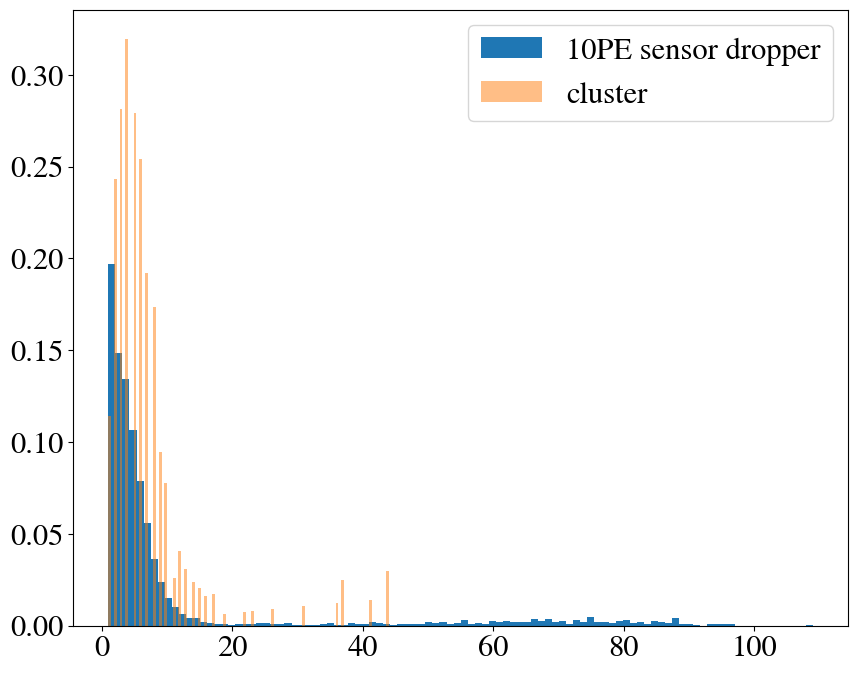

In [71]:
plt.hist(dst_sensor_dropper_10PE['numb_of_tracks'], label = '10PE sensor dropper', bins = 100, density = True)
plt.hist(dst_cluster_dropper['numb_of_tracks'], label = 'cluster', bins = 100, density = True, alpha = 0.5)
plt.legend()
plt.show()

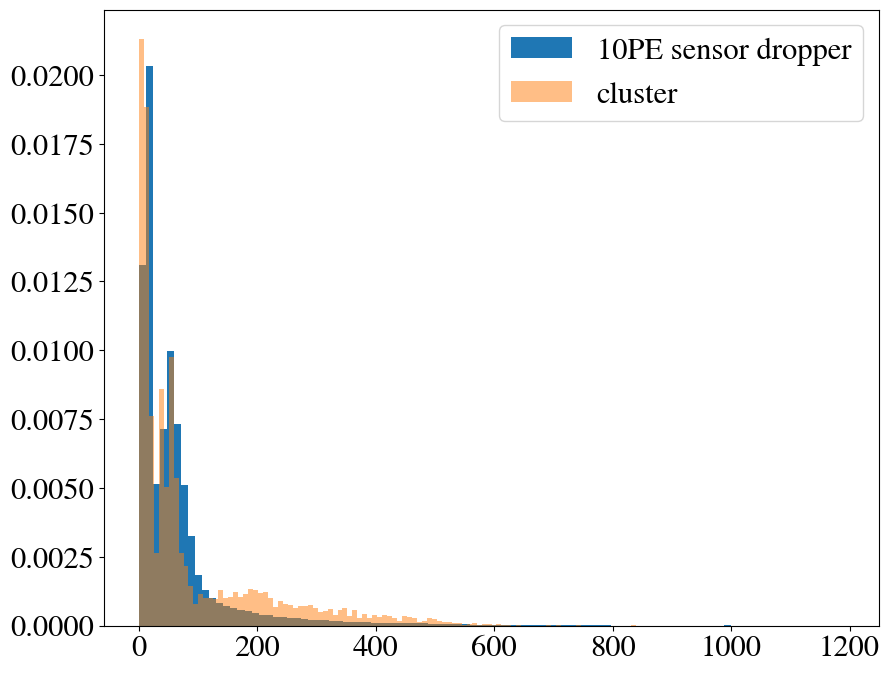

In [12]:
plt.hist(dst_sensor_dropper_10PE['length'], label = '10PE sensor dropper', bins = 100, density = True)
plt.hist(dst_cluster_dropper['length'], label = 'cluster', bins = 100, density = True, alpha = 0.5)
plt.legend()
plt.show()

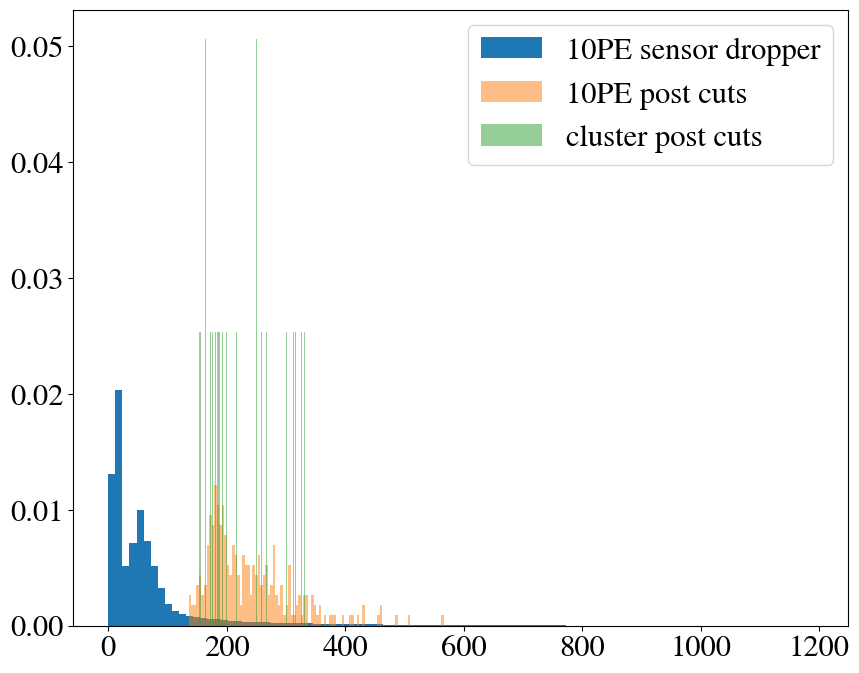

In [13]:
sensor_10PE_hdst
plt.hist(dst_sensor_dropper_10PE['length'], label = '10PE sensor dropper', bins = 100, density = True)
plt.hist(sensor_10PE_hdst['length'], label = '10PE post cuts', bins = 100, density = True, alpha = 0.5)
plt.hist(cluster_hdst['length'], label = 'cluster post cuts', bins = 100, density = True, alpha = 0.5)

plt.legend()
plt.show()

In [21]:
# how many events in the DEP erange have energy distributed across multiple tracks relatively evenly?
event_E_proportionality = []

for evt, df in tqdm(dst_sensor_dropper_10PE.groupby('event')):
    if (df.energy.sum() < 1.8) and (df.energy.sum() > 1.4):
        if df.iloc[0].numb_of_tracks > 1:
            # check how much of total energy is made up of most energetic track
            event_E_proportionality.append(df[df.trackID == 0].energy.values[0]/df.energy.sum())

  0%|          | 0/74618 [00:00<?, ?it/s]

In [23]:
# how many events in the DEP erange have energy distributed across multiple tracks relatively evenly?
event_E_proportionality_cluster = []

for evt, df in tqdm(dst_cluster_dropper.groupby('event')):
    if (df.energy.sum() < 1.8) and (df.energy.sum() > 1.4):
        if df.iloc[0].numb_of_tracks > 1:
            # check how much of total energy is made up of most energetic track
            event_E_proportionality_cluster.append(df[df.trackID == 0].energy.values[0]/df.energy.sum())

  0%|          | 0/1748 [00:00<?, ?it/s]

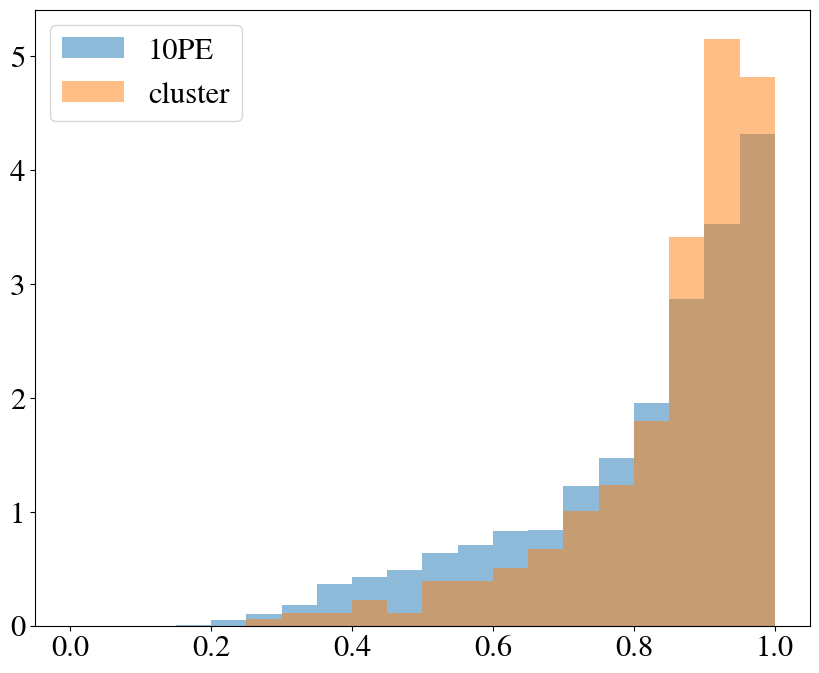

In [26]:
plt.hist(event_E_proportionality, label = '10PE', alpha = 0.5, density = True, bins = 20, range = [0, 1])
plt.hist(event_E_proportionality_cluster, label = 'cluster', alpha = 0.5, density = True, bins = 20, range = [0, 1])
plt.legend()
plt.show()

In [165]:
# DEP data
E = dst_sensor_dropper_10PE.groupby('event').energy.transform('sum')
sensor_dropper_10PE_DEP = dst_sensor_dropper_10PE[(E > 1.6) & (E < 1.8)]

E = dst_cluster_dropper.groupby('event').energy.transform('sum')
cluster_dropper_DEP = dst_cluster_dropper[(E > 1.6) & (E < 1.8)]


In [166]:
display(cluster_dropper_DEP)
display(sensor_dropper_10PE_DEP)

,event,trackID,energy,length,numb_of_voxels,numb_of_hits,numb_of_tracks,x_min,y_min,z_min,...,blob1_z,blob2_x,blob2_y,blob2_z,eblob1,eblob2,ovlp_blob_energy,vox_size_x,vox_size_y,vox_size_z
0,515526,0,1.579466,160.531258,352,962,3,134.375,291.575,732.0,...,747.947315,165.475,353.775000,809.760602,0.358715,0.298029,0.000000,14.729545,14.678571,14.920635
1,515526,1,0.020160,20.794710,2,6,3,-312.575,-155.875,-88.0,...,-84.022877,-312.575,-140.325000,-84.022877,0.020160,0.020160,0.020160,14.729545,14.678571,14.920635
2,515526,2,0.017279,0.000000,1,5,3,-297.025,-185.975,-92.0,...,-85.494072,-297.025,-172.039626,-85.494072,0.017279,0.017279,0.017279,14.729545,14.678571,14.920635
0,650052,0,1.756684,253.528063,419,894,1,-50.225,-448.825,44.0,...,67.927863,104.275,-325.425000,191.320657,0.378779,0.264872,0.000000,14.517647,14.367857,14.285714
0,1197480,0,1.620684,136.178142,340,957,1,119.825,-294.325,1004.0,...,1076.067632,165.475,-217.575000,1032.451219,0.400242,0.344083,0.019277,14.087500,14.170833,13.777778
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5,1028208,0,1.593192,348.496437,485,1182,3,257.775,-16.925,388.0,...,426.400246,304.425,229.875000,532.034579,0.206308,0.123712,0.000000,14.862963,14.862963,14.736842
6,1028208,1,0.036837,0.000000,1,4,3,257.775,322.175,304.0,...,313.249505,257.775,322.175000,313.249505,0.036837,0.036837,0.036837,14.862963,14.862963,14.736842
7,1028208,2,0.018454,21.019404,2,6,3,104.275,152.625,336.0,...,343.557894,119.825,152.625000,343.557894,0.018454,0.018454,0.018454,14.862963,14.862963,14.736842
0,497237,0,1.621101,196.855869,378,866,1,-250.375,-217.575,128.0,...,147.172583,-112.425,-109.725000,218.590627,0.410219,0.349376,0.000000,14.517647,14.367857,13.500000


,event,trackID,energy,length,numb_of_voxels,numb_of_hits,numb_of_tracks,x_min,y_min,z_min,...,blob1_z,blob2_x,blob2_y,blob2_z,eblob1,eblob2,ovlp_blob_energy,vox_size_x,vox_size_y,vox_size_z
22,927320,0,0.972680,137.265087,138,406,5,-81.325,291.575,756.0,...,790.512323,-65.775,353.775,773.304274,0.450027,0.293991,0.004809,14.777083,14.681707,14.943396
23,927320,1,0.369063,65.161870,34,92,5,196.575,353.775,636.0,...,652.499238,227.675,369.325,652.499238,0.362762,0.362762,0.362762,14.777083,14.681707,14.943396
24,927320,2,0.217541,65.161870,27,67,5,-435.975,-140.325,24.0,...,38.094391,-404.875,-124.775,38.094391,0.202511,0.202511,0.202511,14.777083,14.681707,14.943396
25,927320,3,0.107833,44.045122,14,36,5,-126.975,338.225,748.0,...,759.810651,-96.875,353.775,759.810651,0.107833,0.107833,0.107833,14.777083,14.681707,14.943396
26,927320,4,0.003580,0.000000,1,1,5,10.975,446.075,708.0,...,708.000000,10.975,446.075,708.000000,0.003580,0.003580,0.003580,14.777083,14.681707,14.943396
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
19,1703893,3,0.112980,29.989189,6,18,8,243.225,337.725,1136.0,...,1136.000000,257.775,353.275,1136.000000,0.112980,0.112980,0.112980,14.994595,14.808000,15.000000
20,1703893,4,0.089433,35.882030,7,19,8,-19.125,106.975,996.0,...,1005.030115,-19.125,122.525,1005.030115,0.089433,0.089433,0.089433,14.994595,14.808000,15.000000
21,1703893,5,0.086299,36.068624,7,16,8,335.525,106.475,1336.0,...,1341.274162,351.075,122.025,1341.274162,0.086299,0.086299,0.086299,14.994595,14.808000,15.000000
22,1703893,6,0.036052,14.994595,2,8,8,-34.675,446.075,-452.0,...,-446.631007,-34.675,446.075,-446.631007,0.036052,0.036052,0.036052,14.994595,14.808000,15.000000


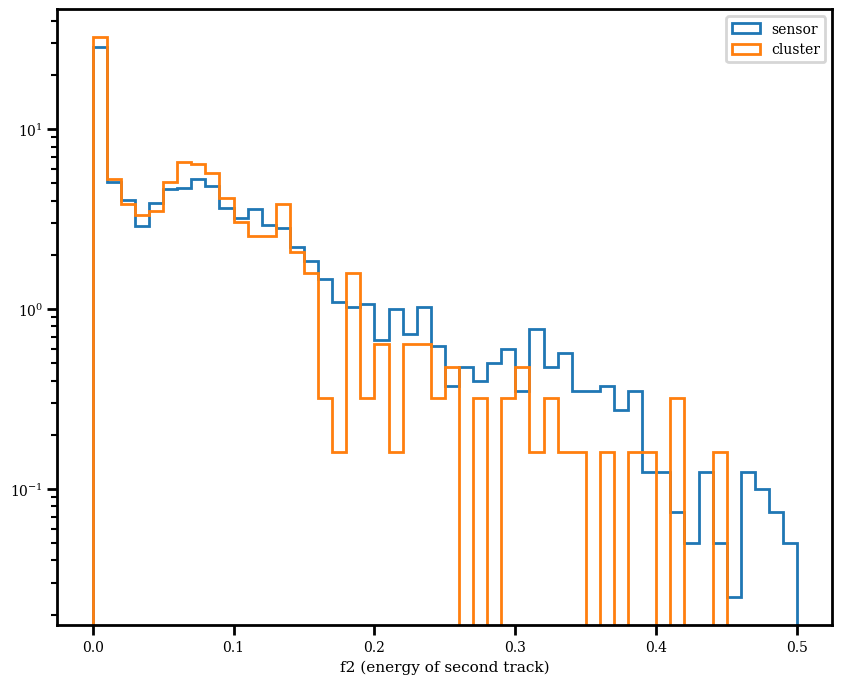

In [167]:
def split_metrics(dst, lo=1.4, hi=1.8):
    E = dst.groupby('event').energy.sum()
    d = dst[dst.event.map(E).between(lo, hi, inclusive='neither')].copy()
    d['f'] = d.energy / d.event.map(E)
    d['rank'] = d.groupby('event').f.rank(ascending=False, method='first')
    out = d.pivot(index='event', columns='rank', values='f')
    res = pd.DataFrame({
        'f1': out[1],
        'f2': out[2].fillna(0) if 2 in out else 0,
        'n_tracks': d.groupby('event').size(),
        'N_eff': 1 / (d.f**2).groupby(d.event).sum(),
    })
    return res

m_cluster = split_metrics(cluster_dropper_DEP)
m_sensor  = split_metrics(sensor_dropper_10PE_DEP)

for m, lab in [(m_sensor, 'sensor'), (m_cluster, 'cluster')]:
    plt.hist(m.f2, bins=50, range=(0, 0.5), density=True,
             histtype='step', label=lab)
plt.yscale('log'); plt.xlabel('f2 (energy of second track)'); plt.legend()
plt.show()

In [164]:
display(m_cluster)
display(m_sensor)

,f1,f2,n_tracks,N_eff
event,,,,
2535,1.0,0,1,1.0
5696,1.0,0,1,1.0
7132,1.0,0,1,1.0
8165,1.0,0,1,1.0
11518,1.0,0,1,1.0
...,...,...,...,...
5950149,1.0,0,1,1.0
5959375,1.0,0,1,1.0
5968349,1.0,0,1,1.0


,f1,f2,n_tracks,N_eff
event,,,,
429,1.0,0,1,1.0
569,1.0,0,1,1.0
5000,1.0,0,1,1.0
7401,1.0,0,1,1.0
9165,1.0,0,1,1.0
...,...,...,...,...
5997371,1.0,0,1,1.0
5998673,1.0,0,1,1.0
6001718,1.0,0,1,1.0


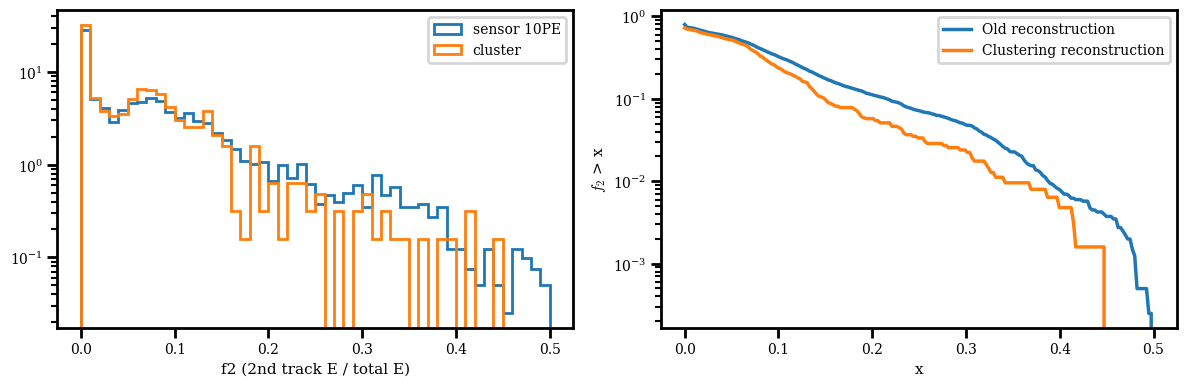

f2 > 0.05: sensor 0.5557, cluster 0.5167
f2 > 0.1: sensor 0.3248, cluster 0.2376
f2 > 0.2: sensor 0.1116, cluster 0.0574
f2 > 0.3: sensor 0.0478, cluster 0.0223


In [168]:
x = np.linspace(0, 0.5, 200)

def frac_above(f2, x):
    f2 = np.sort(f2.to_numpy())
    return 1 - np.searchsorted(f2, x, side='right') / len(f2)

fig, ax = plt.subplots(1, 2, figsize=(12, 4))

# f2 distribution
for m, lab in [(m_sensor, 'sensor 10PE'), (m_cluster, 'cluster')]:
    ax[0].hist(m.f2, bins=50, range=(0, 0.5), density=True,
               histtype='step', label=lab)
ax[0].set_yscale('log')
ax[0].set_xlabel('f2 (2nd track E / total E)')
ax[0].legend()

# fraction of events with f2 > x
for m, lab in [(m_sensor, 'Old reconstruction'), (m_cluster, 'Clustering reconstruction')]:
    ax[1].plot(x, frac_above(m.f2, x), label=lab)
ax[1].set_yscale('log')
ax[1].set_xlabel('x')
ax[1].set_ylabel(r'$f_2$ > x')
ax[1].legend()

plt.tight_layout()
plt.show()

# quoted numbers at a few thresholds
for xc in [0.05, 0.1, 0.2, 0.3]:
    print(f"f2 > {xc}: sensor {(m_sensor.f2 > xc).mean():.4f}, cluster {(m_cluster.f2 > xc).mean():.4f}")

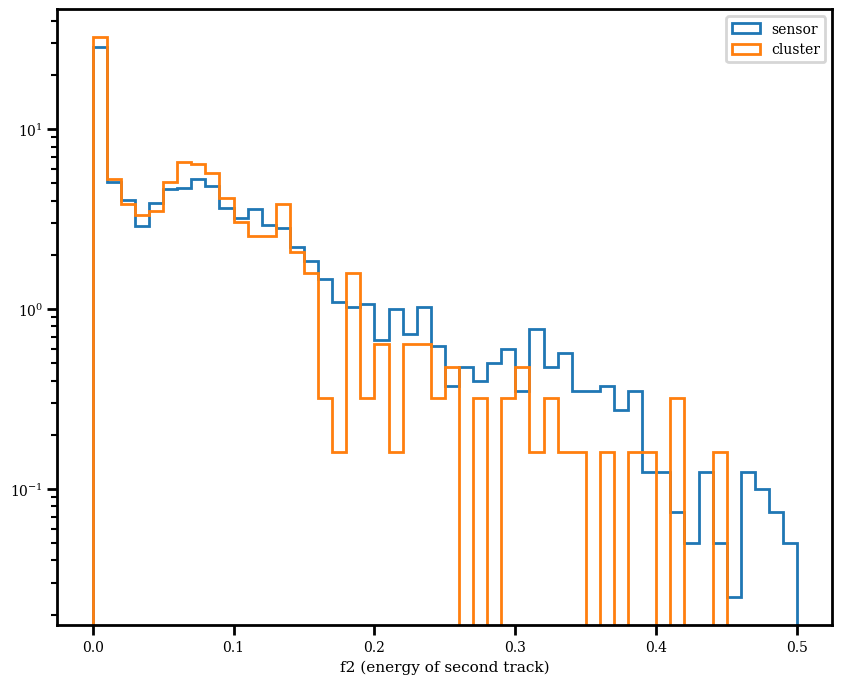

In [169]:
# now with dep (no stats lol)
m_cluster = split_metrics(cluster_dropper_DEP)
m_sensor  = split_metrics(sensor_dropper_10PE_DEP)

for m, lab in [(m_sensor, 'sensor'), (m_cluster, 'cluster')]:
    plt.hist(m.f2, bins=50, range=(0, 0.5), density=True,
             histtype='step', label=lab)
plt.yscale('log'); plt.xlabel('f2 (energy of second track)'); plt.legend()
plt.show()

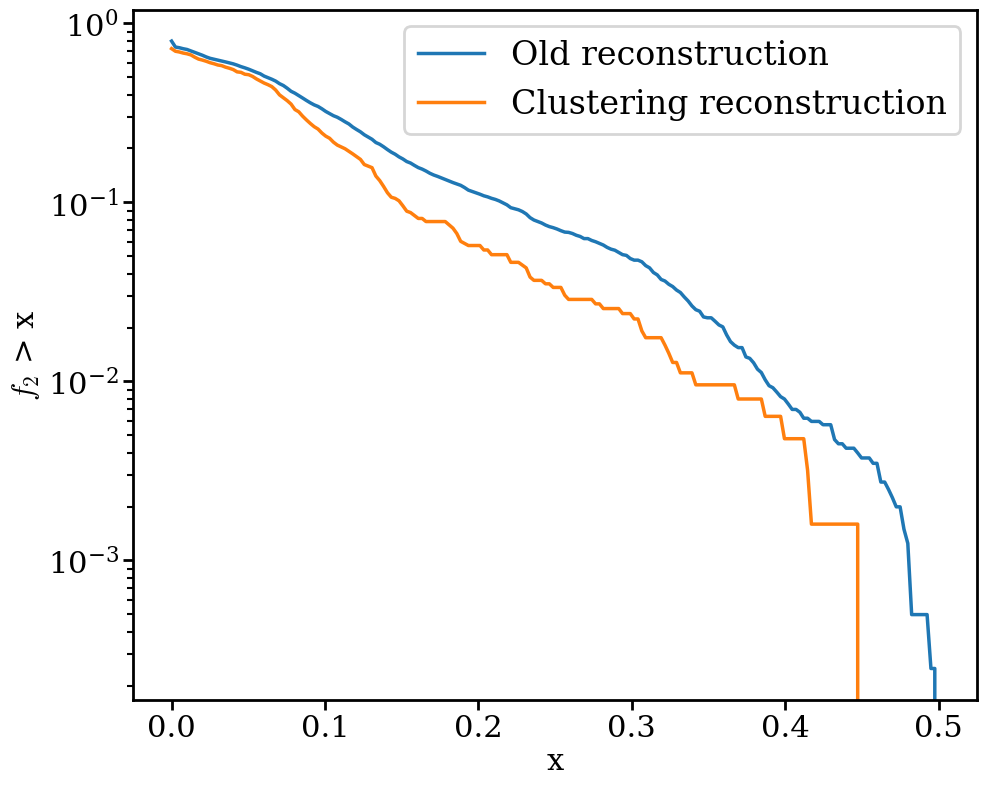

In [170]:
import plot_info

plot_info.apply_style()
plt.rcParams['text.usetex'] = False
plt.rcParams['text.usetex'] = False
plt.rcParams['font.family'] = 'serif'
plt.rcParams['font.serif'] = ['DejaVu Serif']
plt.rcParams['mathtext.fontset'] = 'cm'   # Computer Modern-style maths, bundled with matplotlib
plt.rcParams['lines.linewidth'] = 2.5        # plotted lines
plt.rcParams['axes.linewidth'] = 2           # axes frame / spines
plt.rcParams['xtick.major.width'] = 2
plt.rcParams['ytick.major.width'] = 2
plt.rcParams['xtick.minor.width'] = 1.5
plt.rcParams['ytick.minor.width'] = 1.5
plt.rcParams['xtick.major.size'] = 7         # tick length
plt.rcParams['ytick.major.size'] = 7
plt.rcParams['xtick.minor.size'] = 4
plt.rcParams['ytick.minor.size'] = 4
plt.rcParams['patch.linewidth'] = 2          # histogram/bar edges
# fraction of events with f2 > x
for m, lab in [(m_sensor, 'Old reconstruction'), (m_cluster, 'Clustering reconstruction')]:
    plt.plot(x, frac_above(m.f2, x), label=lab)
plt.yscale('log')
plt.xlabel('x', fontsize = 22)
plt.ylabel(r'$f_2$ > x', fontsize = 22)
plt.xticks(fontsize = 22)
plt.yticks(fontsize = 22)
plt.legend(fontsize = 24)

plt.tight_layout()
plt.savefig('old_new_clustering_f2.pdf')
plt.show()

In [13]:

sensor_hdst, sensors_efficiencies = func.apply_cuts(dst_sensor_dropper, 
                                             lower_z = low_z, 
                                             upper_z = upp_z, 
                                             r_lim   = r_lim, 
                                             lower_e = low_e, 
                                             upper_e = upp_e)


Cutting events around fiducial volume related to:
Z range between 20 and 1195
Radius range < 300
Fiducial track cut
Relative Cut efficiency:
Efficiency: 0.01 %
Absolute Cut efficiency:
Efficiency: 0.01 %
One track cut
Relative Cut efficiency:
Efficiency: 0.00 %
Absolute Cut efficiency:
Efficiency: 0.00 %

Blob overlap cut
Relative Cut efficiency:


ZeroDivisionError: division by zero

In [ ]:
display(tdst)
plt.hist(tdst.groupby('event').energy.sum(), bins = 100)
plt.xlabel('Energy (MeV)')
plt.show()

Cutting events around fiducial volume related to:
Z range between 20 and 1195
Radius range < 300
Fiducial track cut
Relative Cut efficiency:
Efficiency: 100.00 %
Absolute Cut efficiency:
Efficiency: 100.00 %
One track cut
Relative Cut efficiency:
Efficiency: 99.87 %
Absolute Cut efficiency:
Efficiency: 99.87 %

Blob overlap cut
Relative Cut efficiency:
Efficiency: 100.00 %
Absolute Cut efficiency:
Efficiency: 100.00 %
Energy cut
Relative Cut efficiency:
Efficiency: 100.00 %
Absolute Cut efficiency:
Efficiency: 100.00 %


,Cut,Relative Efficiency,Relative Events,Single Cut Efficiency
0,No cuts,100.000000,20118,100.000000
1,Fiducial Cuts,100.000000,20118,100.000000
2,One track cut,99.865792,20091,99.865792
3,Blob overlap cuts,100.000000,20091,100.000000
4,Energy cuts,100.000000,20091,100.000000


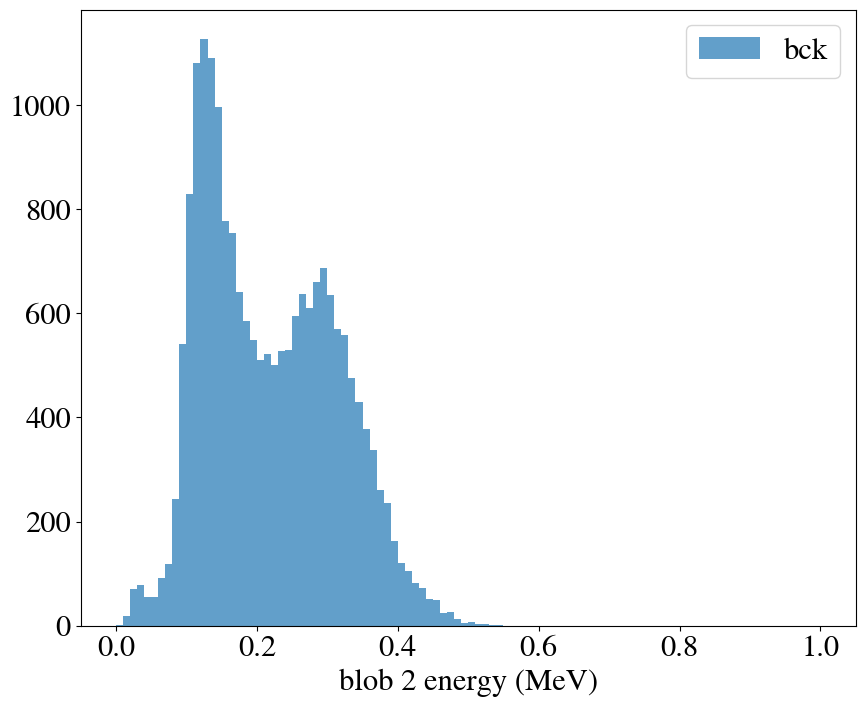

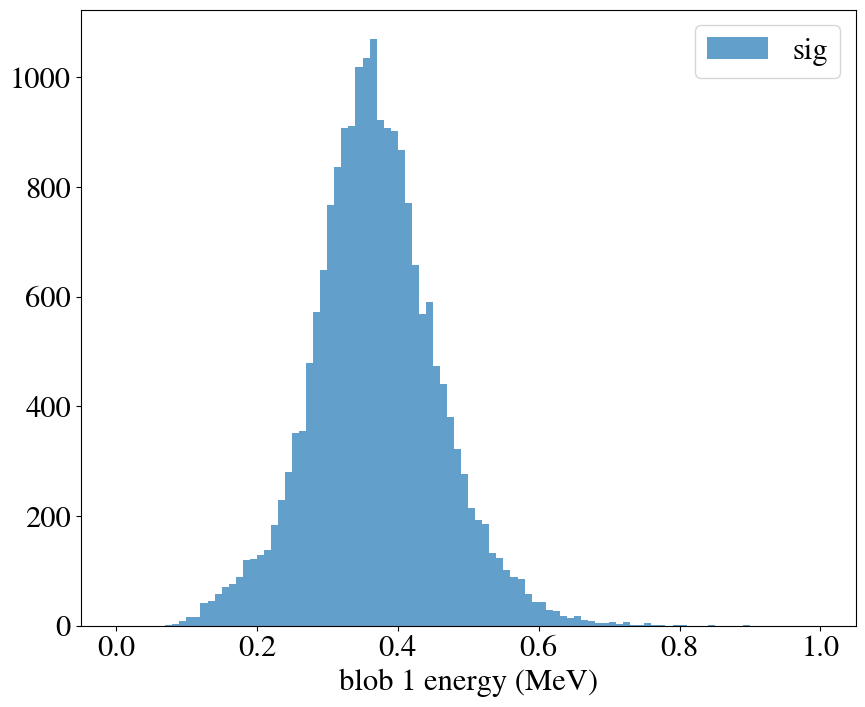

In [22]:
if True:
    #######################################################################################
    #########################   CUT PARAMETERS   #####################################
    #######################################################################################
    low_z = 20
    upp_z  = 1195
    r_lim = 300
    low_e = 1.4
    upp_e = 1.8

    cut_hdst, efficiencies = func.apply_cuts(tdst, 
                                             lower_z = low_z, 
                                             upper_z = upp_z, 
                                             r_lim   = r_lim, 
                                             lower_e = low_e, 
                                             upper_e = upp_e)

    display(efficiencies)


    # signal vs background blob 2 distro
    plt.hist(cut_hdst.eblob2.values, label = 'bck', range = [0, 1], bins = 100, alpha = 0.7)

    plt.xlabel('blob 2 energy (MeV)')
    plt.legend()
    plt.show()


        # signal vs background blob 2 distro

    plt.hist(cut_hdst.eblob1.values, label = 'sig', range = [0, 1], bins = 100, alpha = 0.7)
    
    plt.xlabel('blob 1 energy (MeV)')
    plt.legend()
    plt.show()

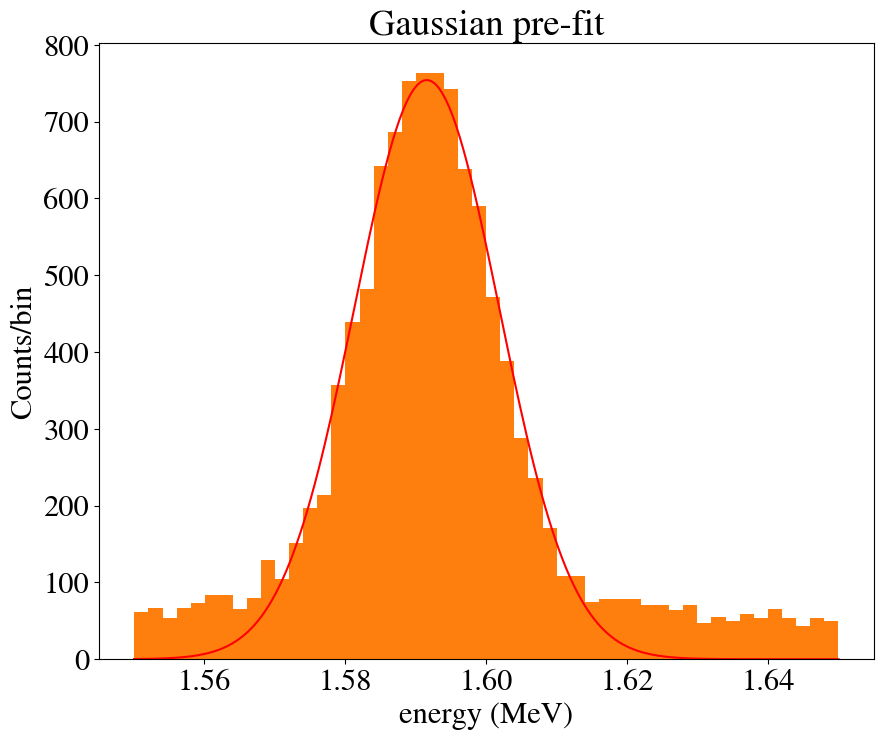

Blob cut: 0.0 MeV
Signal events: 8262.930056507503
Background events: 6237.234289393412
Total events by addition: 14500.164345900914
Total events by row counting: 20091
FOM: 1.0 +/- 0.017950170638149583


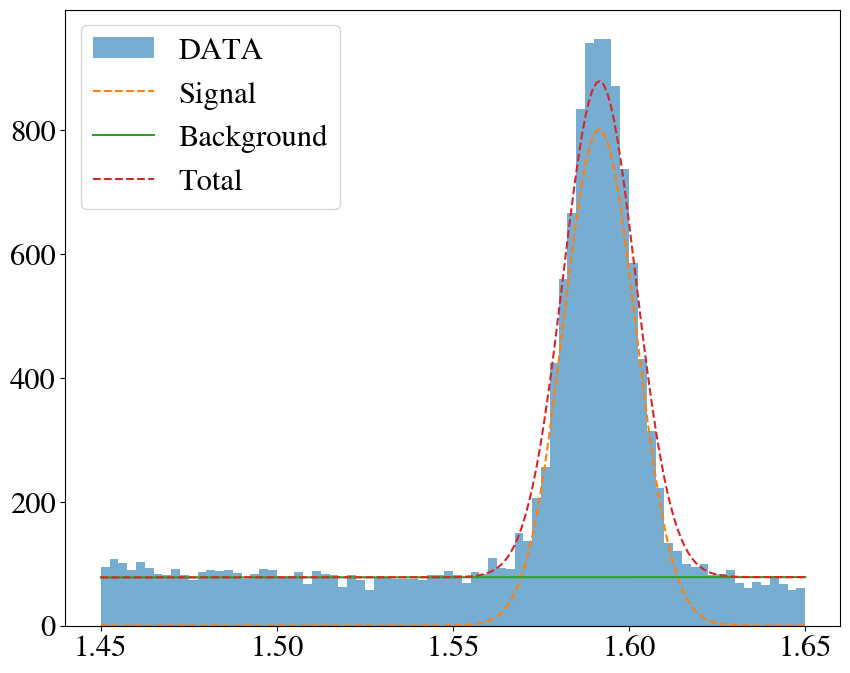

Blob cut: 0.016666666666666666 MeV
Signal events: 8259.716482775018
Background events: 6237.447940263043
Total events by addition: 14497.164423038063
Total events by row counting: 20085
FOM: 0.9995939654980182 +/- 0.017944155011807857


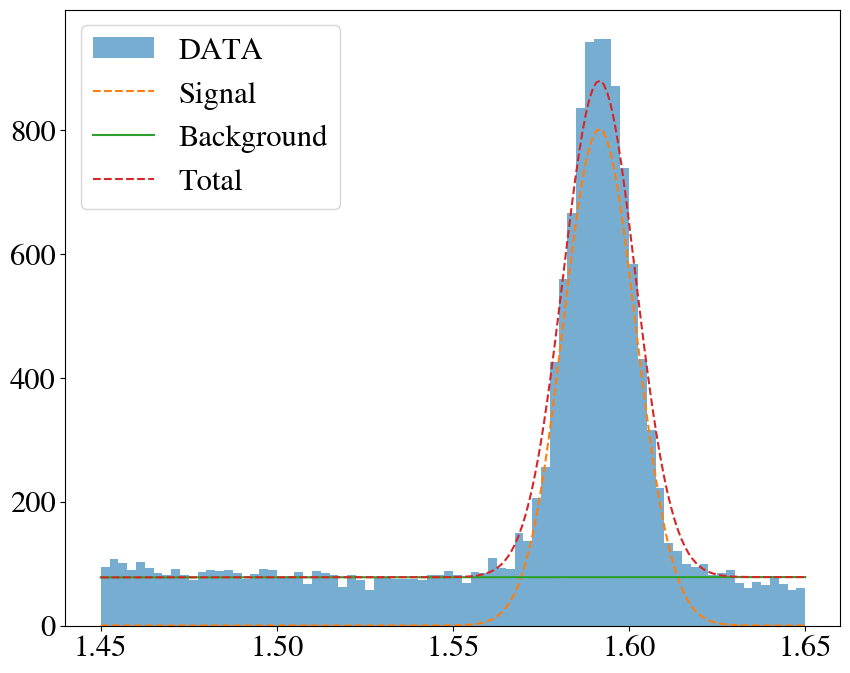

Blob cut: 0.03333333333333333 MeV
Signal events: 8224.502630912582
Background events: 6189.693996738996
Total events by addition: 14414.196627651578
Total events by row counting: 19969
FOM: 0.9991645260475497 +/- 0.017959462792464652


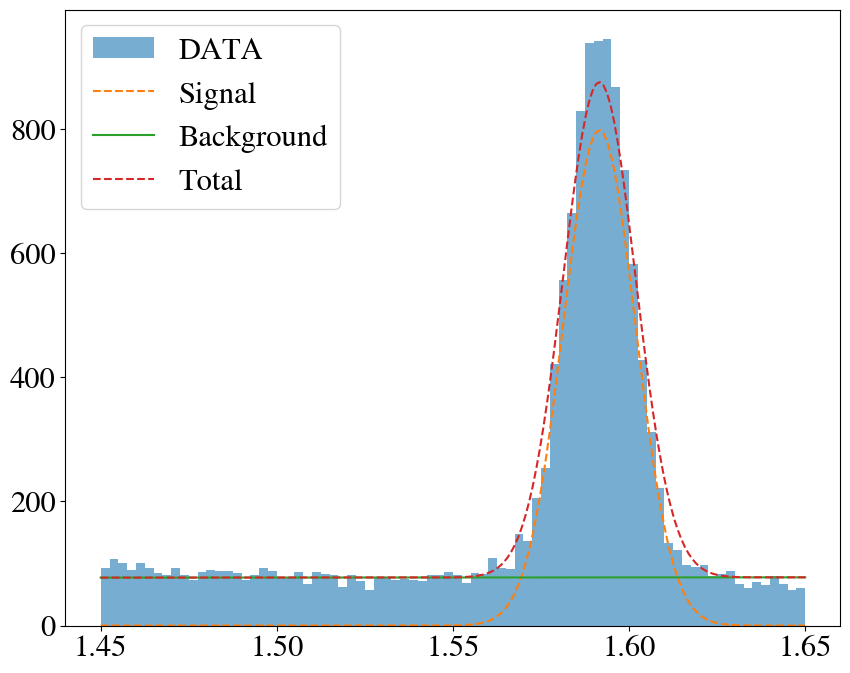

Blob cut: 0.05 MeV
Signal events: 8197.509408438971
Background events: 6150.7077664330745
Total events by addition: 14348.217174872047
Total events by row counting: 19867
FOM: 0.9990364400093938 +/- 0.017975392371145586


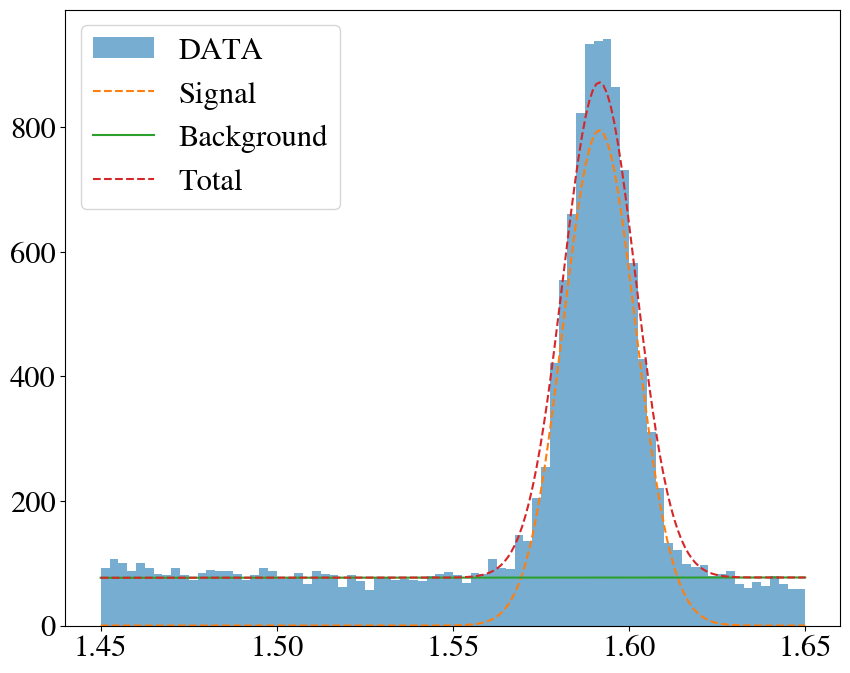

Blob cut: 0.06666666666666667 MeV
Signal events: 8161.392260238022
Background events: 6112.837424804081
Total events by addition: 14274.229685042103
Total events by row counting: 19756
FOM: 0.9977110479700102 +/- 0.01797348040698112


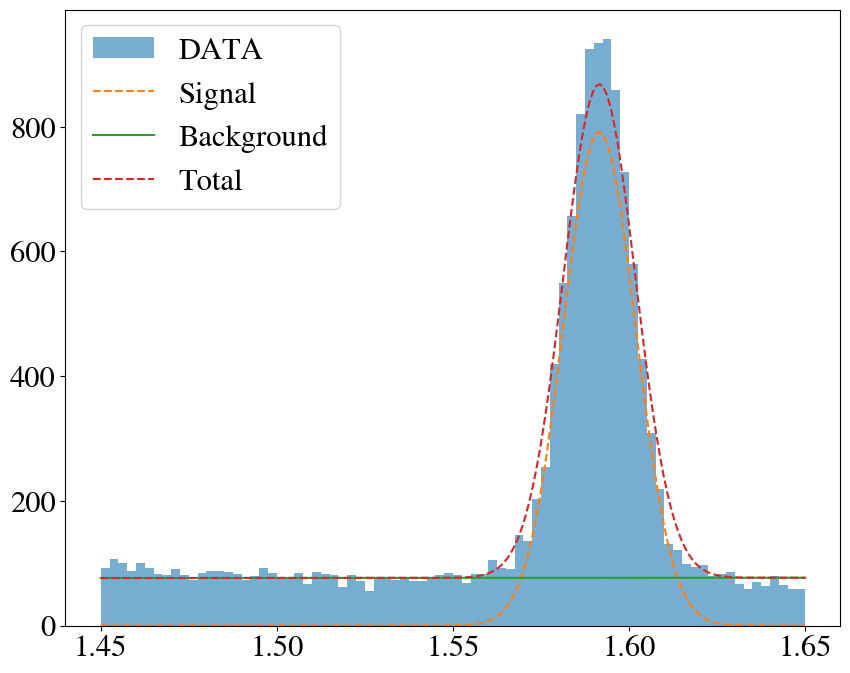

Blob cut: 0.08333333333333333 MeV
Signal events: 8122.3723630685345
Background events: 6030.869289753785
Total events by addition: 14153.241652822318
Total events by row counting: 19540
FOM: 0.9996659272866112 +/- 0.018040423623014095


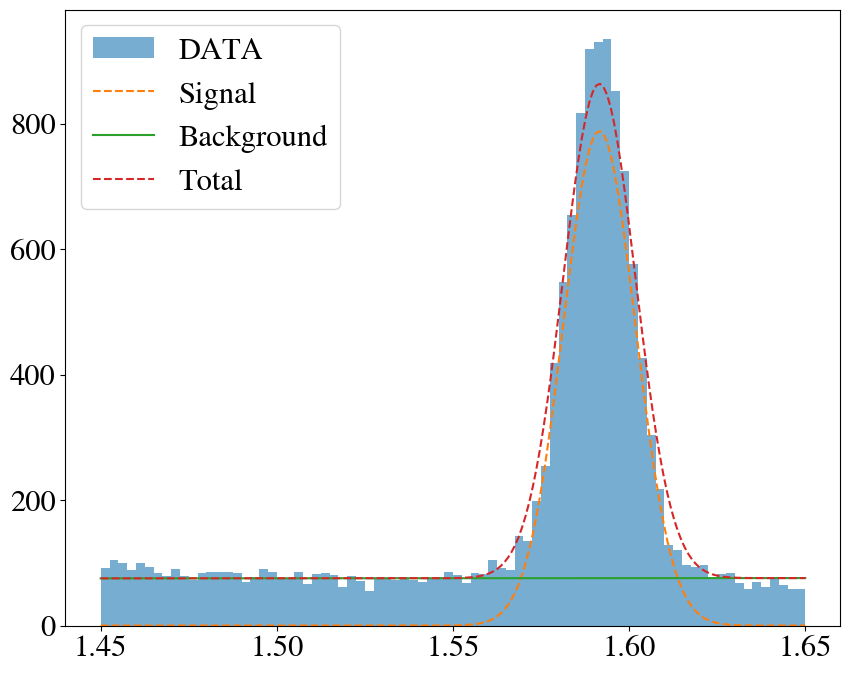

Blob cut: 0.1 MeV
Signal events: 8086.186875944322
Background events: 5686.964579892864
Total events by addition: 13773.151455837185
Total events by row counting: 18817
FOM: 1.02486217444463 +/- 0.018581748328461857


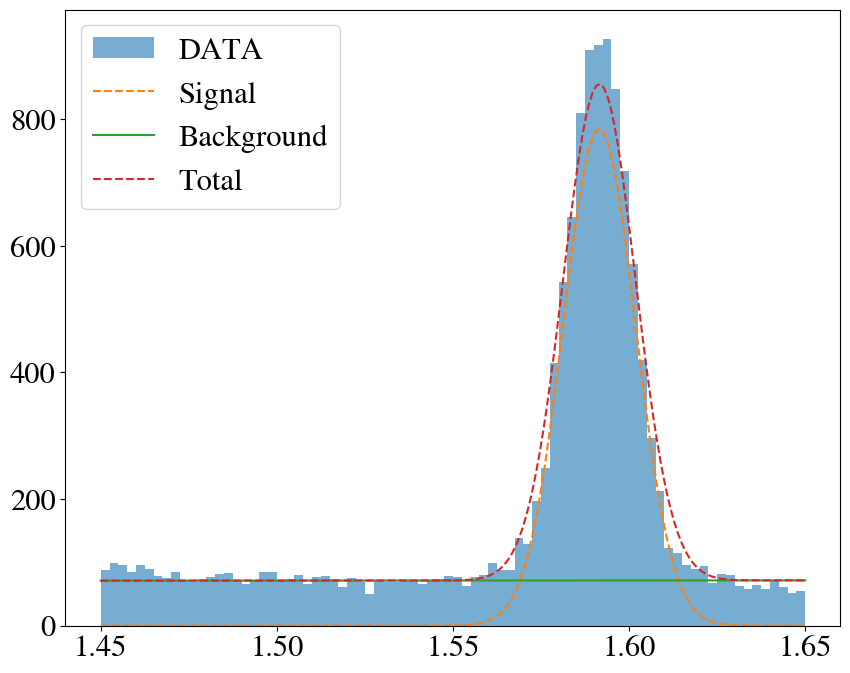

Blob cut: 0.11666666666666667 MeV
Signal events: 8027.92251051078
Background events: 4931.01179962352
Total events by addition: 12958.9343101343
Total events by row counting: 17264
FOM: 1.0926903388398106 +/- 0.02004034223260212


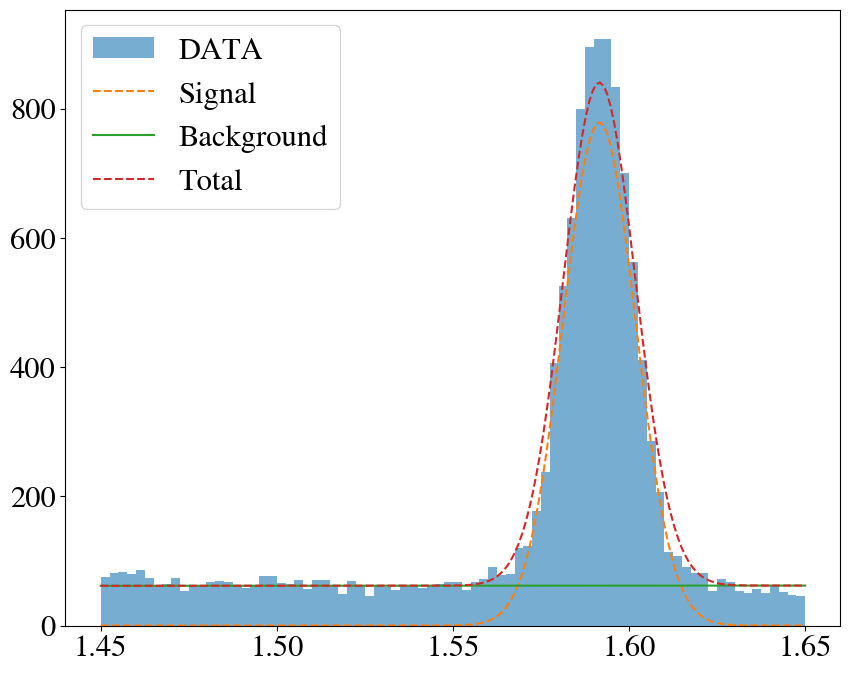

Blob cut: 0.13333333333333333 MeV
Signal events: 7916.621966130522
Background events: 4034.654572175689
Total events by addition: 11951.27653830621
Total events by row counting: 15426
FOM: 1.1912383877003792 +/- 0.022266408865994593


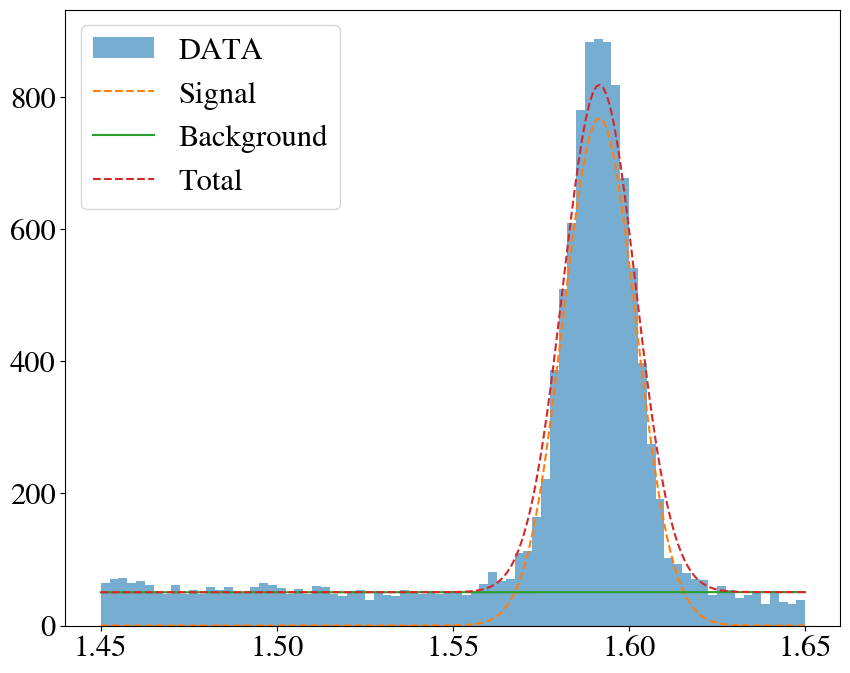

Blob cut: 0.15 MeV
Signal events: 7809.576110647322
Background events: 3197.4172523716093
Total events by addition: 11006.993363018932
Total events by row counting: 13692
FOM: 1.3200481024002566 +/- 0.02530020675368898


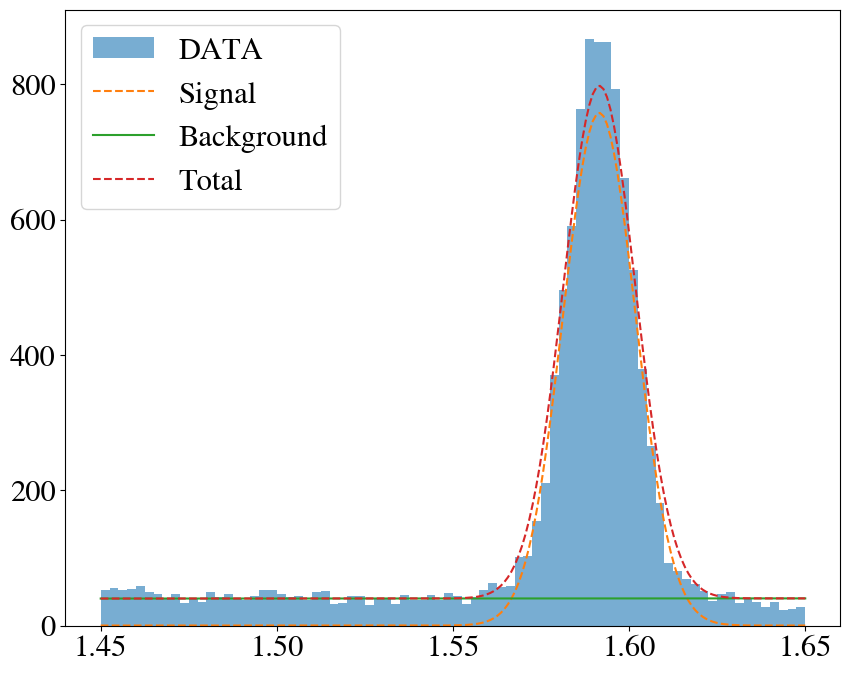

Blob cut: 0.16666666666666666 MeV
Signal events: 7623.356258909859
Background events: 2619.5167278799418
Total events by addition: 10242.8729867898
Total events by row counting: 12401
FOM: 1.4236314715002127 +/- 0.028032080301753092


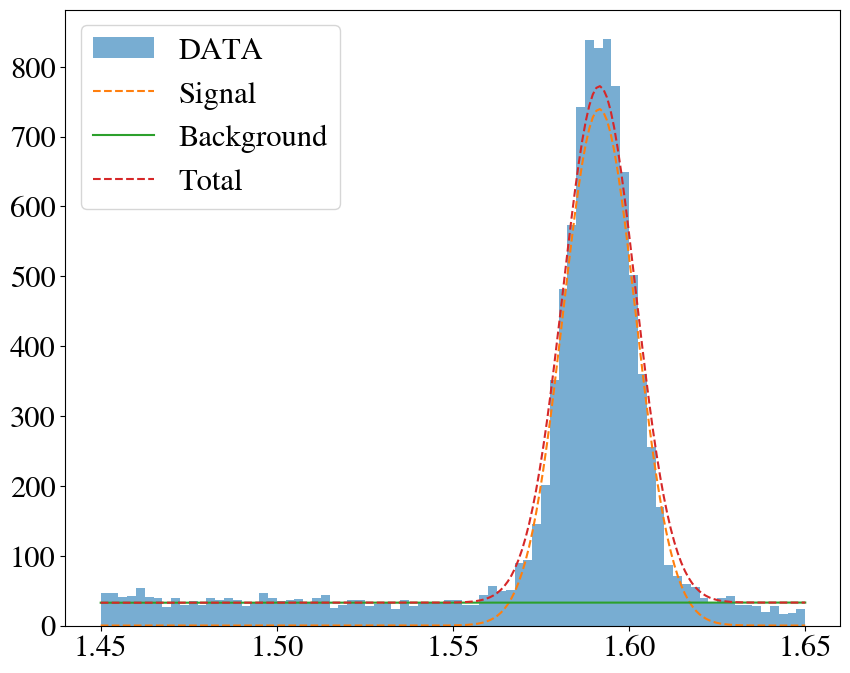

Blob cut: 0.18333333333333332 MeV
Signal events: 7417.709984437775
Background events: 2158.474372582927
Total events by addition: 9576.184357020702
Total events by row counting: 11312
FOM: 1.5260134216660046 +/- 0.03096489018146911


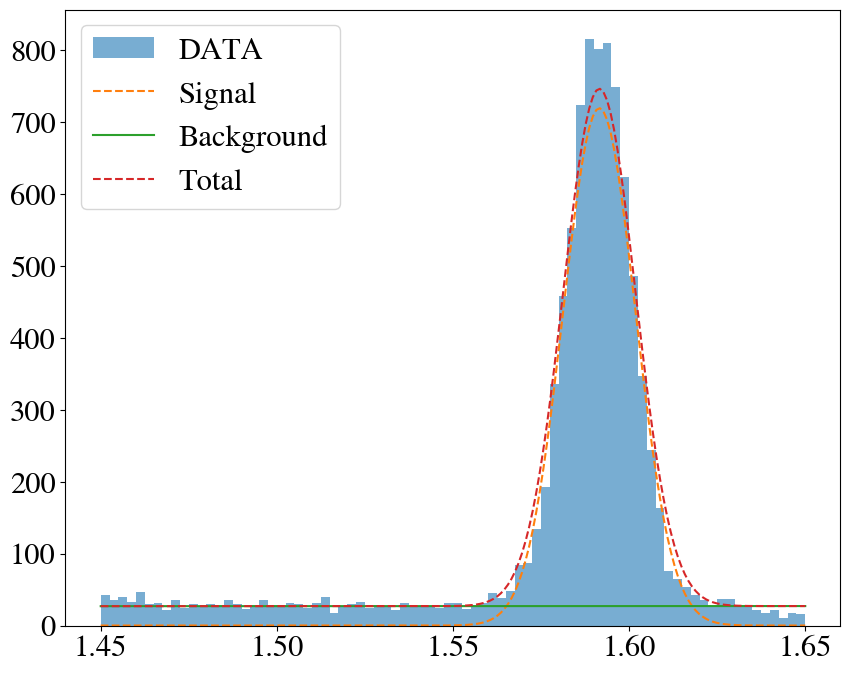

Blob cut: 0.2 MeV
Signal events: 7198.828084298024
Background events: 1780.2532999428029
Total events by addition: 8979.081384240826
Total events by row counting: 10386
FOM: 1.6307329813640616 +/- 0.034223847209168455


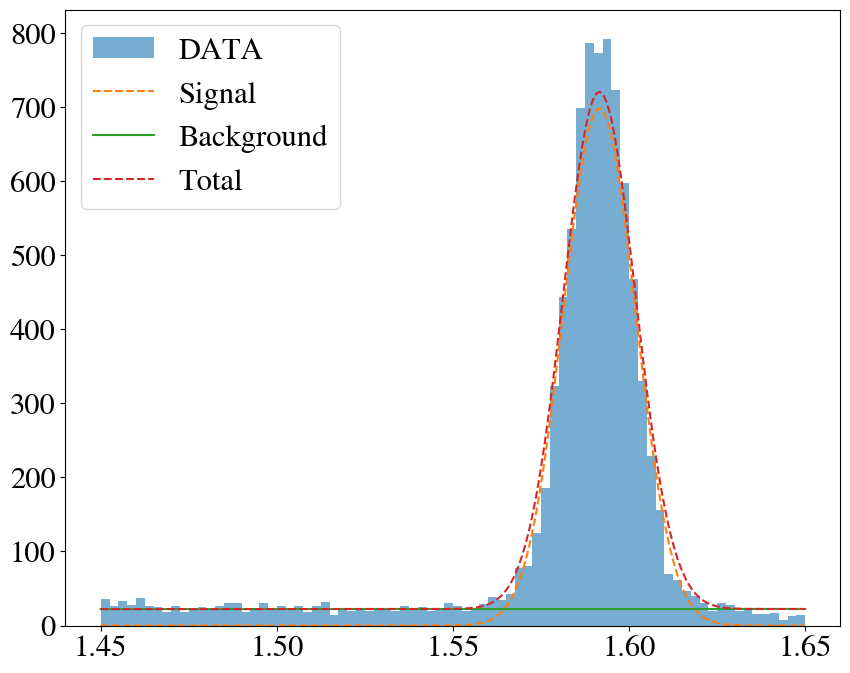

Blob cut: 0.21666666666666667 MeV
Signal events: 6899.3517259513155
Background events: 1467.7145972829624
Total events by addition: 8367.066323234278
Total events by row counting: 9522
FOM: 1.721271710861571 +/- 0.037568635419516244


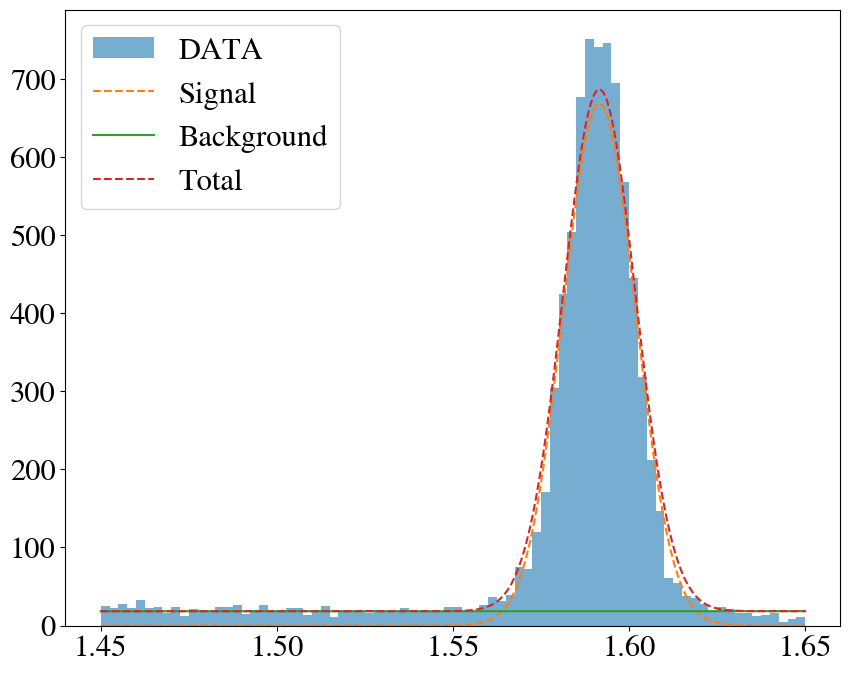

Blob cut: 0.23333333333333334 MeV
Signal events: 6488.572297731166
Background events: 1214.3932401371462
Total events by addition: 7702.965537868313
Total events by row counting: 8688
FOM: 1.7796370136254374 +/- 0.040624304866391216


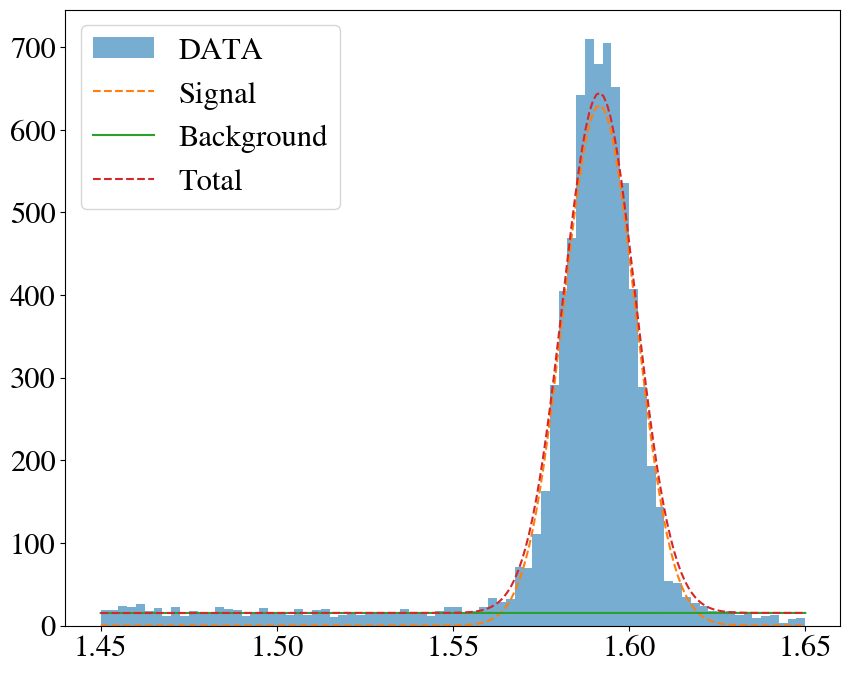

Blob cut: 0.25 MeV
Signal events: 5966.432549172888
Background events: 1023.6138192407659
Total events by addition: 6990.046368413654
Total events by row counting: 7798
FOM: 1.7824141341053994 +/- 0.04266421064816814


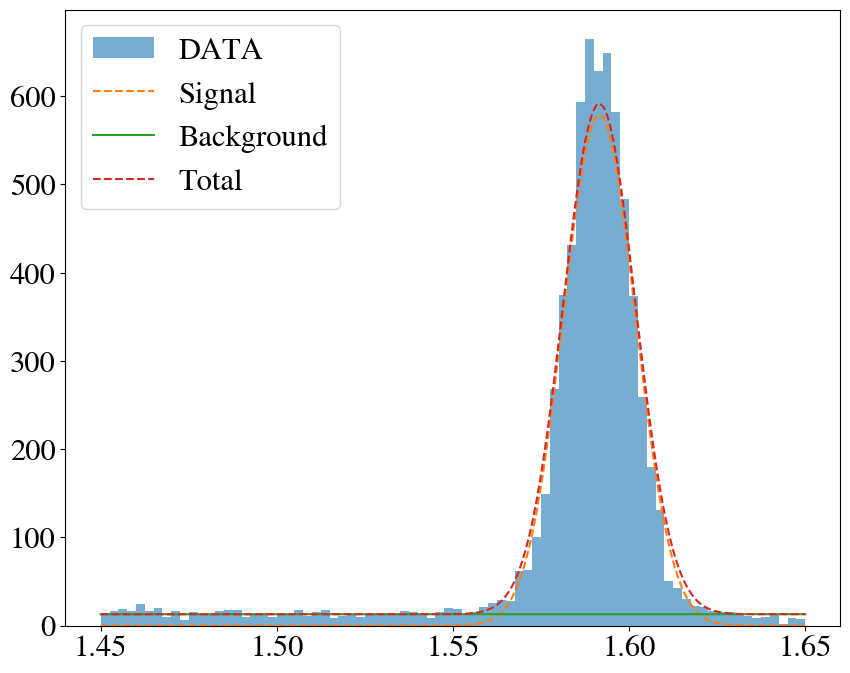

Blob cut: 0.26666666666666666 MeV
Signal events: 5261.475750222631
Background events: 852.1823613834184
Total events by addition: 6113.65811160605
Total events by row counting: 6778
FOM: 1.7226746185462312 +/- 0.04373454912778064


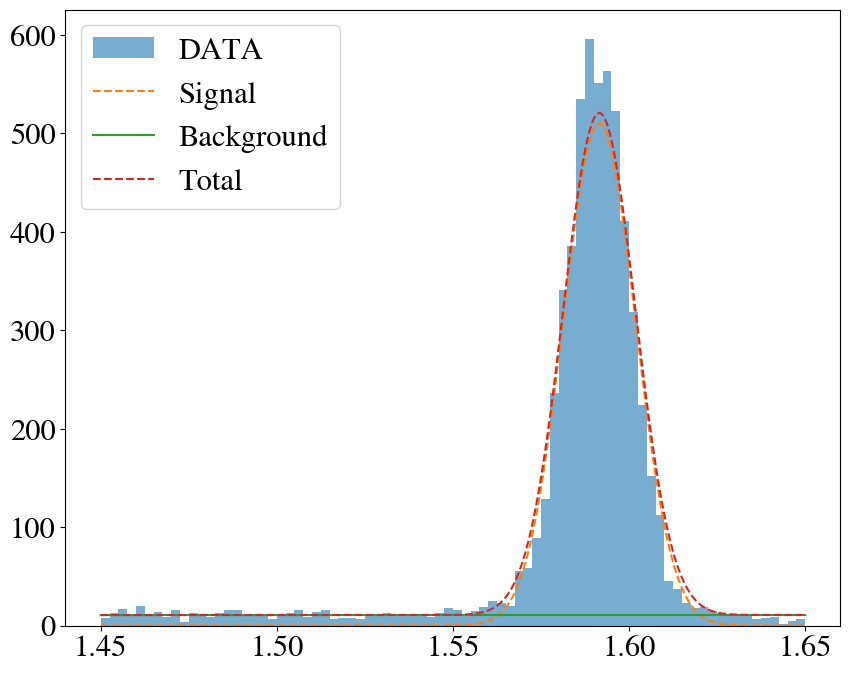

Blob cut: 0.2833333333333333 MeV
Signal events: 4518.071249554765
Background events: 672.7366503975022
Total events by addition: 5190.807899952268
Total events by row counting: 5729
FOM: 1.6649166000923592 +/- 0.04571868679694714


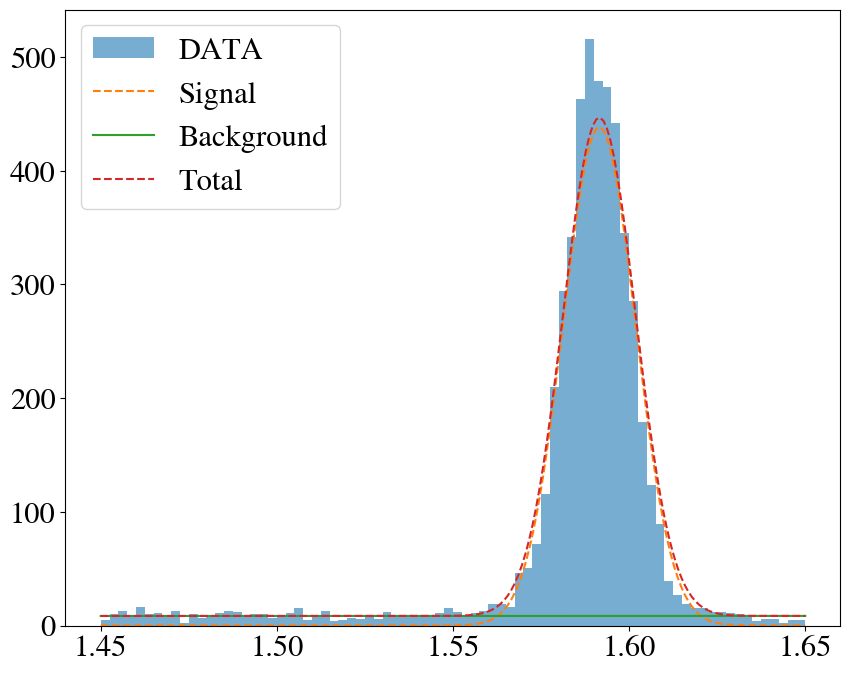

Blob cut: 0.3 MeV
Signal events: 3672.0160872374568
Background events: 504.34129100036466
Total events by addition: 4176.357378237822
Total events by row counting: 4606
FOM: 1.5628031020379018 +/- 0.04763680092234643


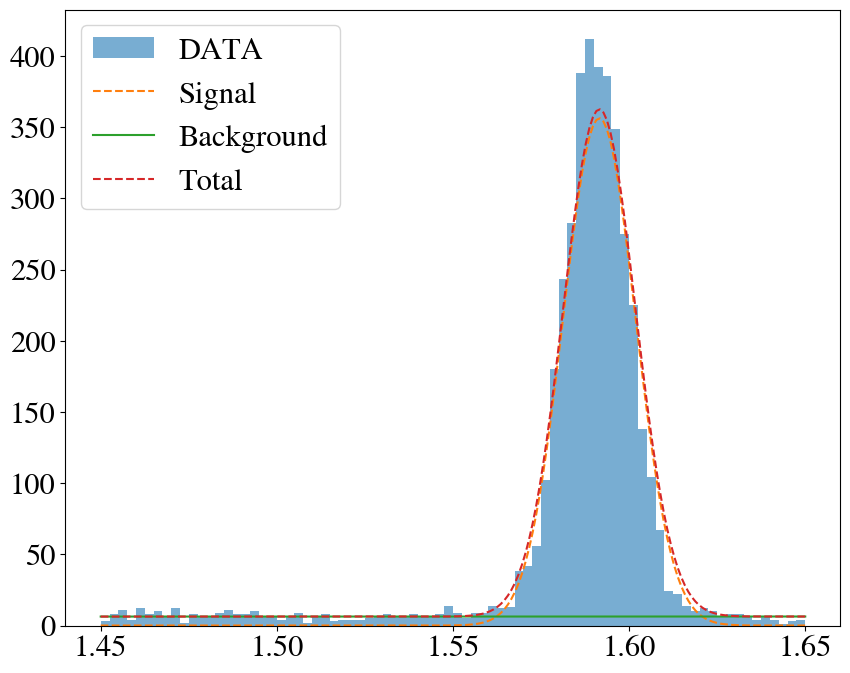

Blob cut: 0.31666666666666665 MeV
Signal events: 2912.42450213324
Background events: 370.6112240585301
Total events by addition: 3283.03572619177
Total events by row counting: 3582
FOM: 1.4459635469798162 +/- 0.04964989478342402


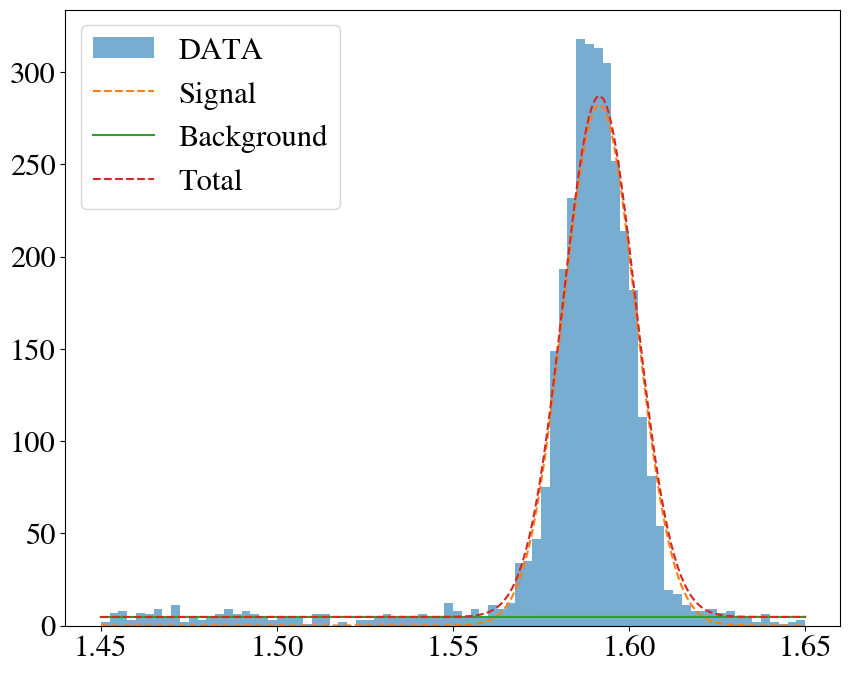

Blob cut: 0.3333333333333333 MeV
Signal events: 2205.830978698677
Background events: 267.1136348954159
Total events by addition: 2472.944613594093
Total events by row counting: 2690
FOM: 1.2899894405755794 +/- 0.0507931513512365


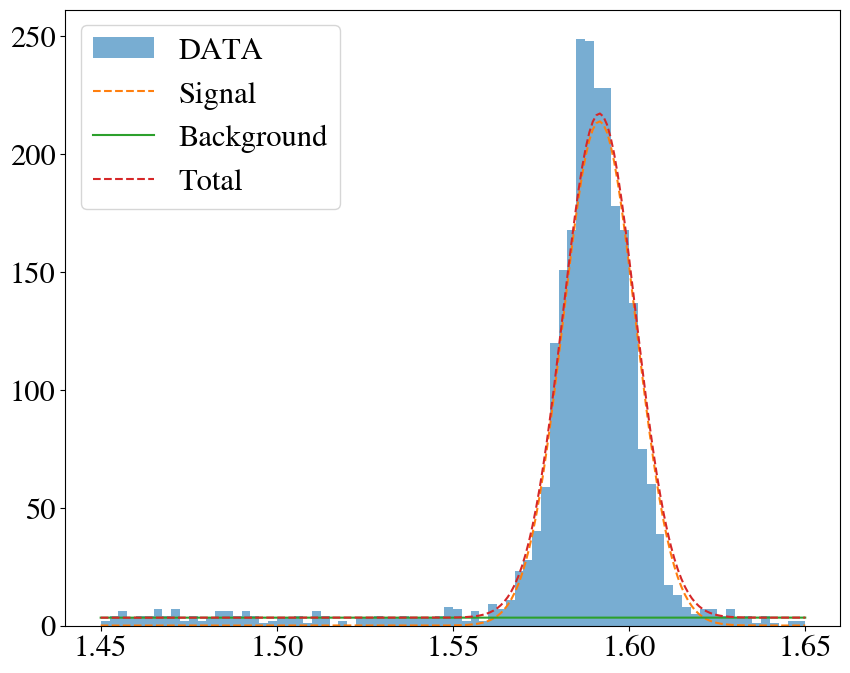

Blob cut: 0.35 MeV
Signal events: 1609.3446034970086
Background events: 179.59684244621653
Total events by addition: 1788.941445943225
Total events by row counting: 1936
FOM: 1.147787925917793 +/- 0.05352288972957216


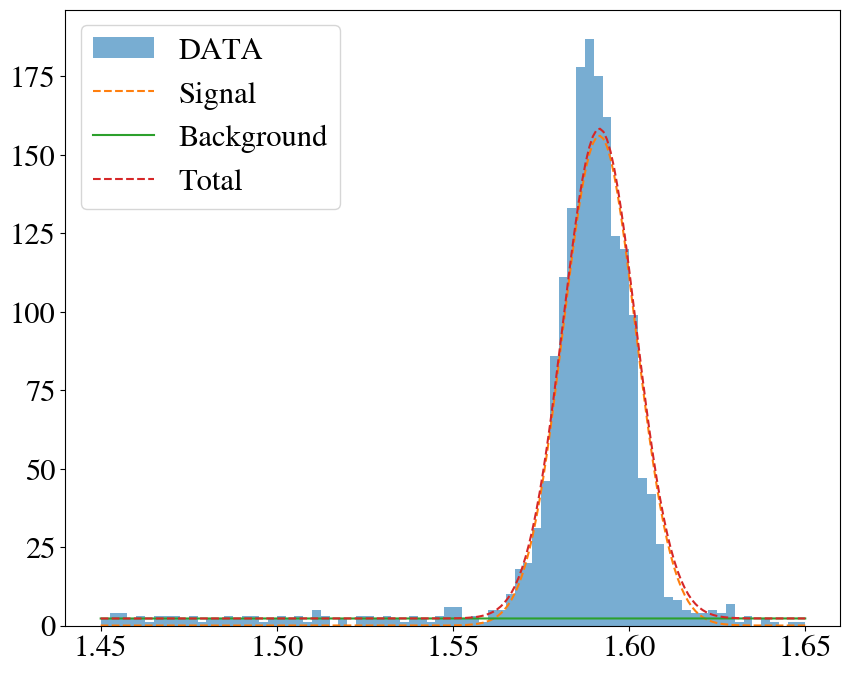

Blob cut: 0.36666666666666664 MeV
Signal events: 1126.0238041509579
Background events: 114.32645270914202
Total events by addition: 1240.3502568600998
Total events by row counting: 1336
FOM: 1.0065518691060231 +/- 0.05725772341967266


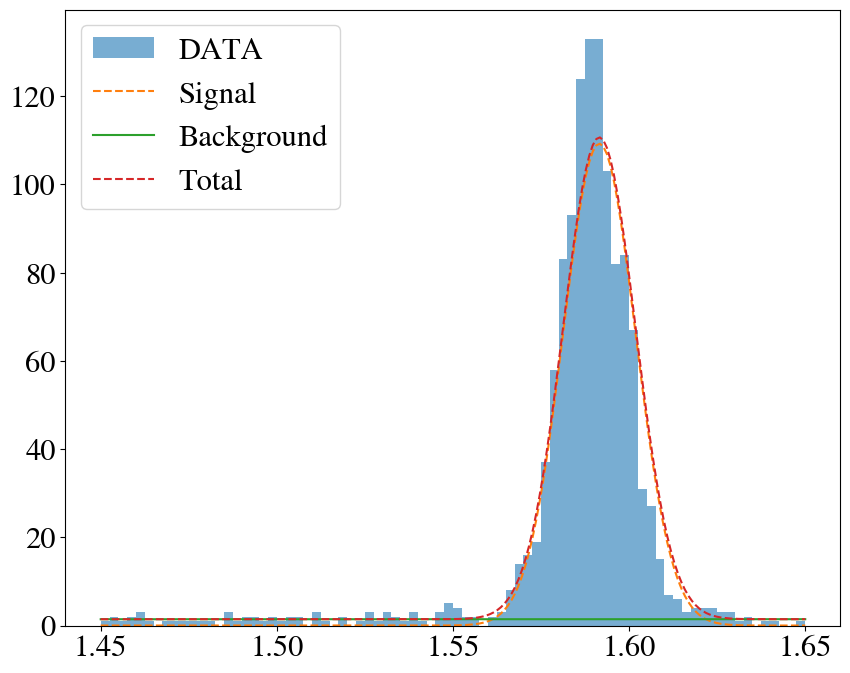

Blob cut: 0.3833333333333333 MeV
Signal events: 748.306008029097
Background events: 68.72083820080128
Total events by addition: 817.0268462298983
Total events by row counting: 877
FOM: 0.8627738239785612 +/- 0.0618276191674654


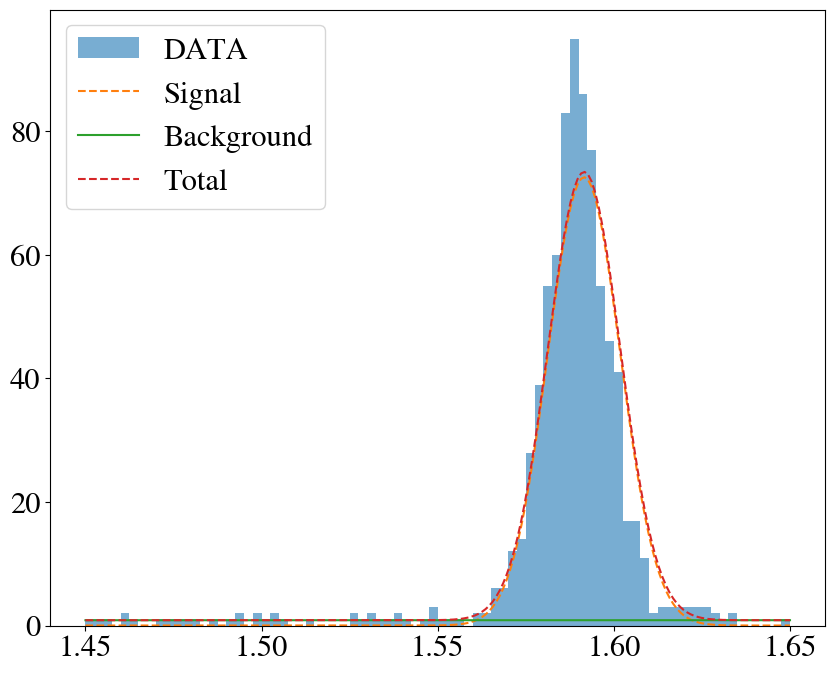

Blob cut: 0.4 MeV
Signal events: 483.071071856622
Background events: 45.59331864815309
Total events by addition: 528.664390504775
Total events by row counting: 564
FOM: 0.6837894264647099 +/- 0.06005856335772989


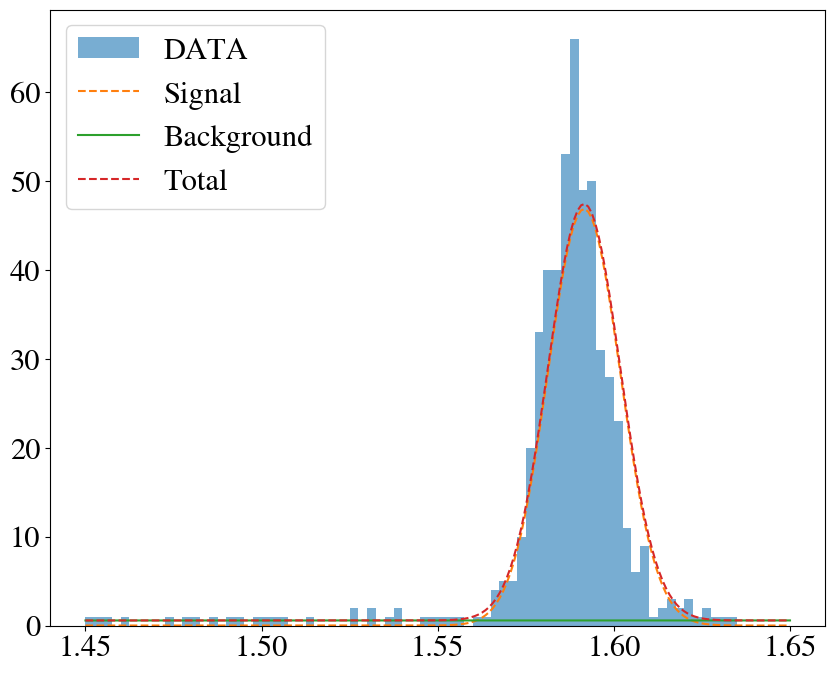

Blob cut: 0.4166666666666667 MeV
Signal events: 314.1702237514941
Background events: 36.82667989707021
Total events by addition: 350.99690364856434
Total events by row counting: 370
FOM: 0.49481822857814217 +/- 0.04980892671509139


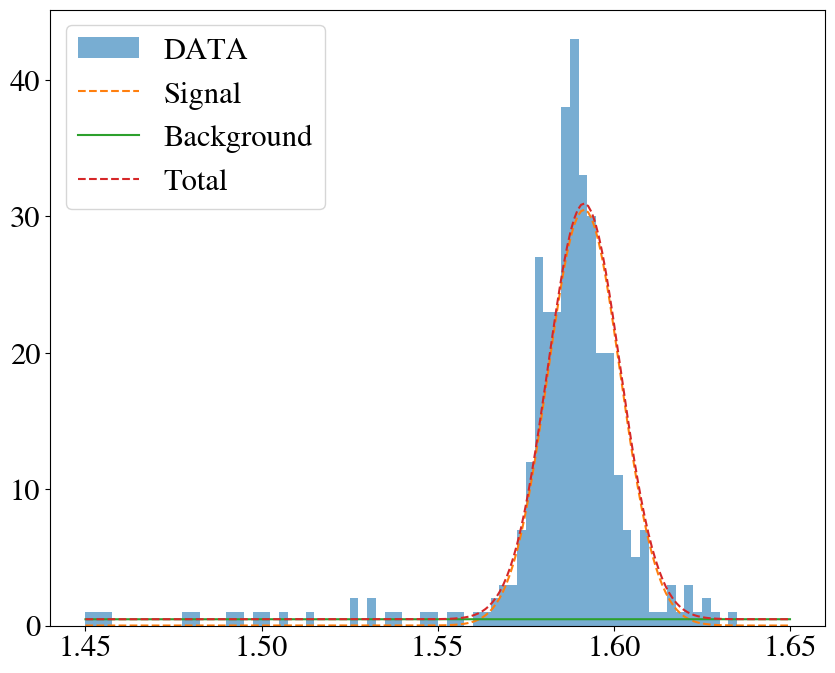

Blob cut: 0.43333333333333335 MeV
Signal events: 185.97260390394118
Background events: 26.077377188968466
Total events by addition: 212.04998109290963
Total events by row counting: 227
FOM: 0.3480799194797196 +/- 0.04280830305398324


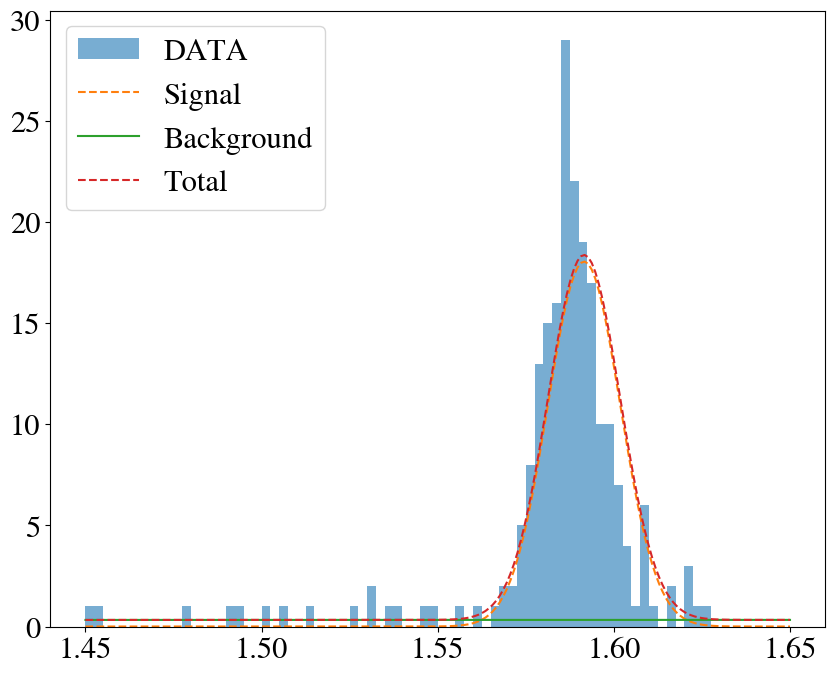

Blob cut: 0.45 MeV
Signal events: 108.99065278135826
Background events: 15.01115429216676
Total events by addition: 124.00180707352503
Total events by row counting: 133
FOM: 0.26887112329545354 +/- 0.04334623245537066


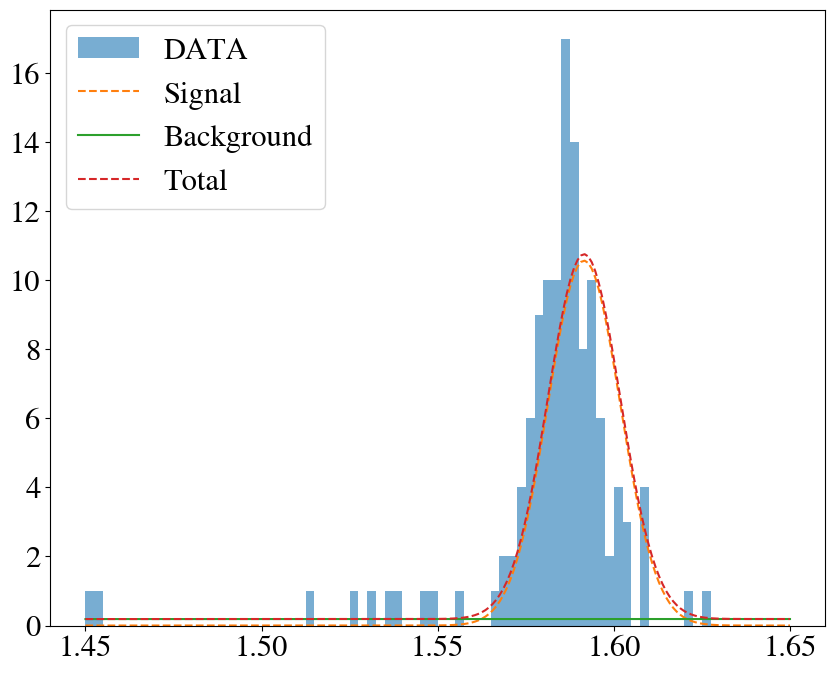

Blob cut: 0.4666666666666667 MeV
Signal events: 52.5053602073217
Background events: 7.482699920008697
Total events by addition: 59.9880601273304
Total events by row counting: 65
FOM: 0.18345790512476617 +/- 0.042082371973201096


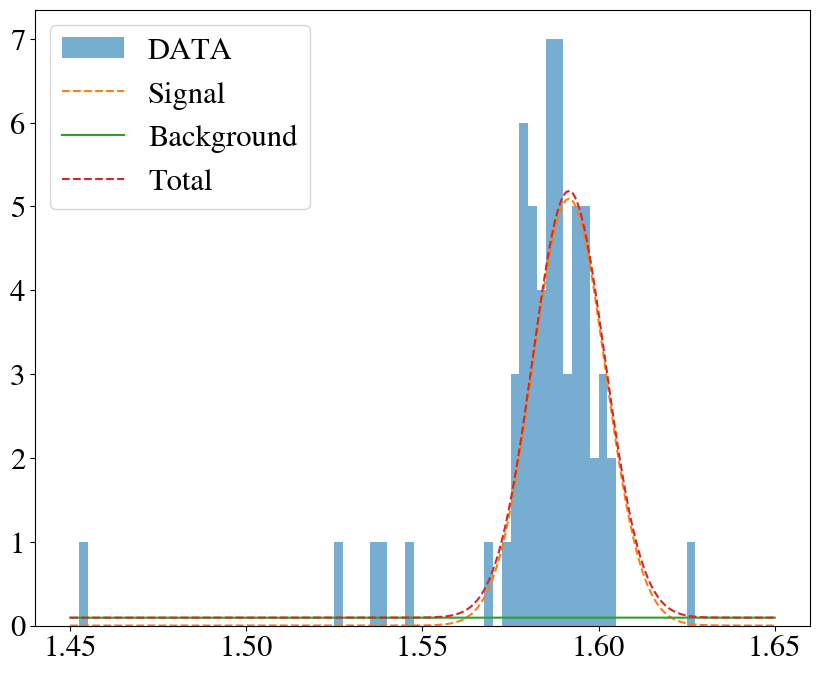

Blob cut: 0.48333333333333334 MeV
Signal events: 21.631504432496723
Background events: 1.3752173093530713
Total events by addition: 23.006721741849795
Total events by row counting: 24
FOM: 0.1763043436274025 +/- 0.08421728822367193


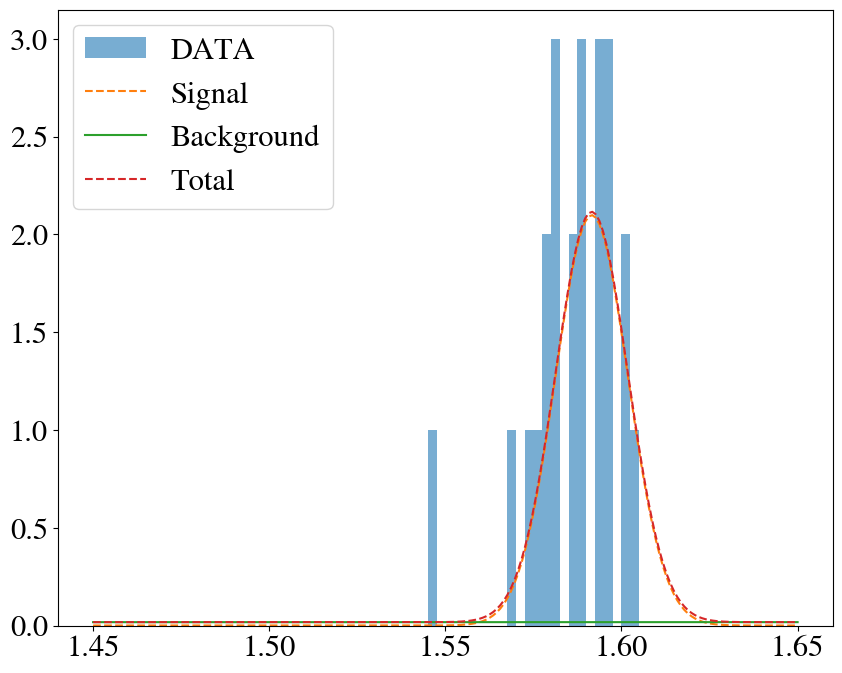

Blob cut: 0.5 MeV
Signal events: 13.655785241447592
Background events: 1.3119050361235753
Total events by addition: 14.967690277571167
Total events by row counting: 16
FOM: 0.11395343758367973 +/- 0.058545092618411176


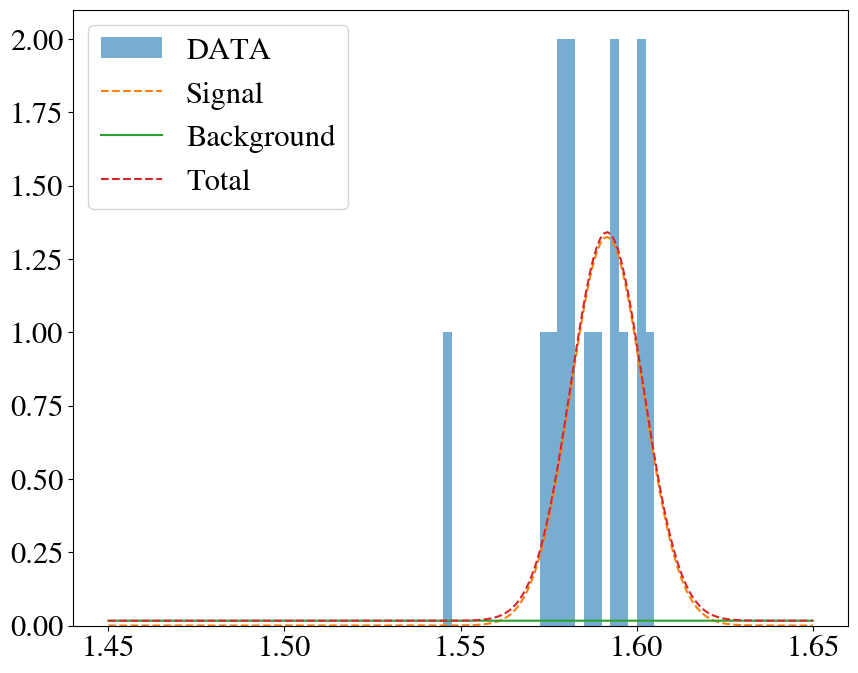

/scratch/halmazan/NEXT/testing/notebooks/MC_truth_FOM/../FOM_functions_050526.py:220: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


In [23]:
cut_list = np.linspace(0, 0.6, 31)
fit_info = dict(bins = 80, fit_range = (1.45, 1.65))

mu_config    = dict(
                value    = 1.59,
                floating = False,
                lower    = 1.4,
                upper    = 1.8)

sigma_config = dict(
                value    = 0.1,
                floating = False,
                lower    = 0)

tau_config   = dict(
                value    = 0.03,
                floating = False,
                lower    = 0,
                upper    = 1)


seeds = dict(
            ns = cut_hdst.event.nunique()/2,
            nb = cut_hdst.event.nunique()/2,
            signal = {'mu_config': mu_config,
                      'sigma_config': sigma_config},
            background = {'lambda_config': tau_config})

# mkdir
Path(f'./output/{RUN_NUMBER_OUT}_{FOM_TS_OUT}').mkdir(parents=True, exist_ok=True)
x = FOM.FOM(cut_hdst, fitf.gaussian_no_N, fitf.exp_no_N, seeds = seeds, fitting_info = fit_info, plot = True, output_path = f'./output/{RUN_NUMBER}_{FOM_TS}')



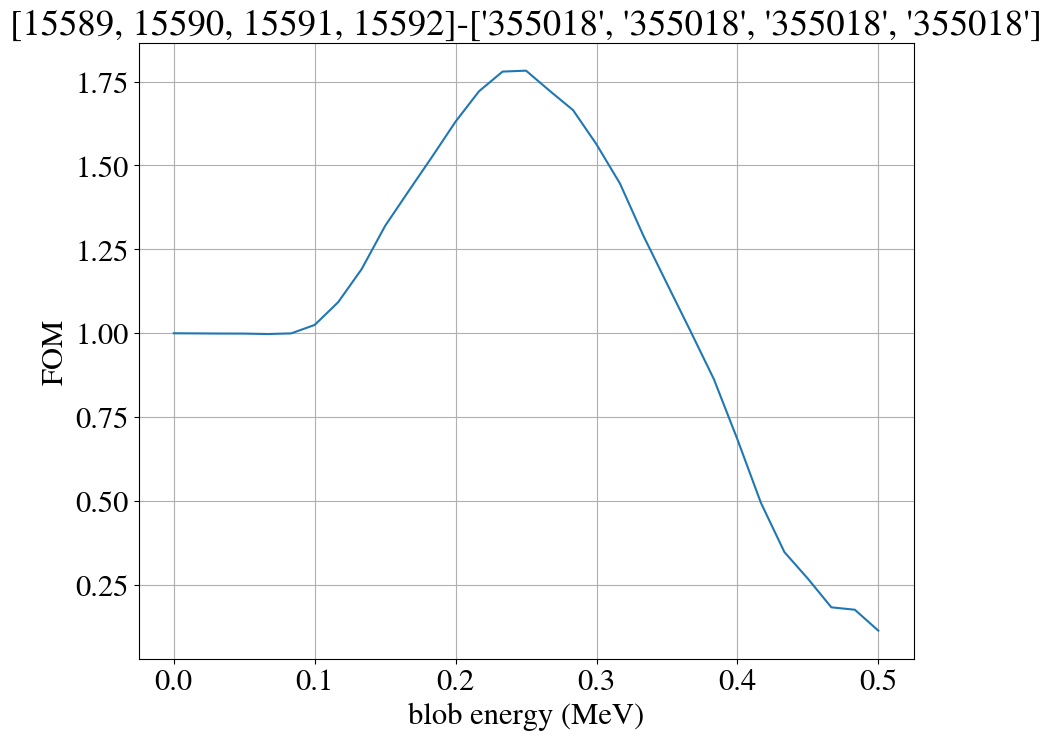

Max FOM as 1.78 at 0.25 MeV
Signal events at peak: 5966.43
Background events at peak: 1023.61
Initial signal events: 8262.93
Initial background events: 6237.23


In [24]:
# load in the csv and visualise
import csv
import matplotlib.pyplot as plt

def read_FOM_csv(path):
    data = np.genfromtxt(path, delimiter=',')
    n    = len(data) // 5

    return dict(
        cut_list = data[0*n : 1*n, 0],
        fom      = data[0*n : 1*n, 1],
        fom_err  = data[1*n : 2*n, 1],
        ns_l     = data[2*n : 3*n, 0],
        nb_l     = data[2*n : 3*n, 1],
        e        = data[3*n : 4*n, 0],
        e_err    = data[3*n : 4*n, 1],
        b        = data[4*n : 5*n, 0],
        b_err    = data[4*n : 5*n, 1],
    )

FOM_info = read_FOM_csv(f'output/{RUN_NUMBER}_{FOM_TS}/FOM.csv')

FOM_clean = FOM_info['fom']
FOM_clean[(FOM_clean > 5) | (FOM_clean < 0)] = 0

plt.plot(FOM_info['cut_list'], FOM_clean)
plt.xlabel('blob energy (MeV)')
plt.title(f'{RUN_NUMBER}-{TIMESTAMP}')
plt.ylabel('FOM')
plt.grid()
plt.show()
max_fom_index = np.argmax(FOM_clean)
max_fom       = FOM_clean[max_fom_index]
cut_pos       = FOM_info['cut_list'][max_fom_index]
print(f'Max FOM as {max_fom:.2f} at {cut_pos:.2f} MeV')
print(f'Signal events at peak: {FOM_info['ns_l'][max_fom_index]:.2f}')
print(f'Background events at peak: {FOM_info['nb_l'][max_fom_index]:.2f}')
print(f'Initial signal events: {FOM_info['ns_l'][0]:.2f}')
print(f'Initial background events: {FOM_info['nb_l'][0]:.2f}')